In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from catboost import CatBoostClassifier
import prince
import umap
import shap
import warnings
warnings.filterwarnings('ignore')

# ── Poster-quality global settings ──────────────────────────────────────────
plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 12,
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans',
})
BLUE, ORANGE = '#4C72B0', '#DD8452'
PALETTE = {'Not Readmitted': BLUE, 'Readmitted': ORANGE}
sns.set_style('whitegrid')

os.makedirs('figures', exist_ok=True)
print("✓ Libraries loaded. Figures will save to ./figures/")


✓ Libraries loaded. Figures will save to ./figures/


In [6]:
# ── Load data ────────────────────────────────────────────────────────────────
df = pd.read_csv('annotated_psychiatric_data_complete.csv')

# ── Outcome ──────────────────────────────────────────────────────────────────
print("Readmissions value counts:")
print(df['Readmissions'].value_counts().sort_index())
df['readmitted'] = (df['Readmissions'].fillna(0) > 0).astype(int)

# ── Demographics ─────────────────────────────────────────────────────────────
df['age'] = pd.to_numeric(df['Pt_Age_Visit'], errors='coerce')
df['age_group'] = pd.cut(df['age'], bins=[5, 9, 11, 13, 19],
                          labels=['6–9', '10–11', '12–13', '14+'], right=True)
df['gender_male'] = (df['GenderCode'].str.strip().str.lower() == 'male').astype(int)
df['insurance_public'] = df['Insurance'].str.contains('AHCCCS', case=False, na=False).astype(int)

# ── ACE score ────────────────────────────────────────────────────────────────
df['ace_score'] = pd.to_numeric(df['ACEscore'], errors='coerce')
df['ace_high'] = (df['ace_score'] >= 4).astype(float)

# ── Restraints ───────────────────────────────────────────────────────────────
df['had_restraints'] = (pd.to_numeric(df['restraints'], errors='coerce').fillna(0) > 0).astype(int)

# ── C-SSRS flags ─────────────────────────────────────────────────────────────
df['csrss_yellow'] = df['Yellow flags (C-SRSS)'].notna().astype(int)
df['csrss_orange'] = df['Orange flags (C-SSRS)'].notna().astype(int)
df['csrss_red']    = df['Red flags (C-SSRS)'].notna().astype(int)
df['csrss_any']    = ((df['csrss_yellow'] + df['csrss_orange'] + df['csrss_red']) > 0).astype(int)

# ── Length of stay (compute before date-quality filter) ──────────────────────
df['VisitDate'] = pd.to_datetime(df['VisitDate'], errors='coerce')
df['DischDate']  = pd.to_datetime(df['DischDate'],  errors='coerce')
df['los_days']   = (df['DischDate'] - df['VisitDate']).dt.days

# ── DATE QUALITY FILTER ───────────────────────────────────────────────────────
# Flag records with impossible or unusable dates and hold them out until reviewed.
flag_missing_visit  = df['VisitDate'].isna()
flag_missing_disch  = df['DischDate'].isna()
flag_negative_los   = df['los_days'].notna() & (df['los_days'] < 0)   # DischDate before VisitDate

flagged = df[flag_missing_visit | flag_missing_disch | flag_negative_los].copy()
flagged['flag_reason'] = ''
flagged.loc[flag_missing_visit[flagged.index], 'flag_reason'] += 'missing_VisitDate; '
flagged.loc[flag_missing_disch[flagged.index], 'flag_reason'] += 'missing_DischDate; '
flagged.loc[flag_negative_los[flagged.index], 'flag_reason']  += f'negative_LOS ({df.loc[flag_negative_los, "los_days"].min():.0f} to {df.loc[flag_negative_los, "los_days"].max():.0f} days); '

if len(flagged) > 0:
    flagged.to_csv('flagged_records_date_errors.csv', index=True)
    print(f"\n{'='*60}")
    print(f"  ⚠  DATE QUALITY FLAGS — {len(flagged)} records excluded")
    print(f"{'='*60}")
    print(f"  Missing VisitDate   : {flag_missing_visit.sum()}")
    print(f"  Missing DischDate   : {flag_missing_disch.sum()}")
    print(f"  Negative LOS        : {flag_negative_los.sum()} "
          f"(range: {df.loc[flag_negative_los,'los_days'].min():.0f} "
          f"to {df.loc[flag_negative_los,'los_days'].max():.0f} days)")
    print(f"\n  Readmission status of flagged records:")
    print(f"    Readmitted     : {flagged['readmitted'].sum()}")
    print(f"    Not readmitted : {(flagged['readmitted']==0).sum()}")
    print(f"\n  Saved for review → flagged_records_date_errors.csv")
    print(f"{'='*60}\n")
else:
    print("\n✓ No date-quality issues found.")

# Exclude flagged records from all downstream analysis
df = df[~(flag_missing_visit | flag_missing_disch | flag_negative_los)].copy()
df = df.reset_index(drop=True)

# ── Diagnostic complexity ─────────────────────────────────────────────────────
def count_csv(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return len([x for x in str(s).split(',') if x.strip()])

def count_dsm5(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return len([x for x in str(s).split(';') if x.strip()])

df['n_visit_diags']   = df['VisitDiags'].apply(count_csv)
df['n_chronic_diags'] = df['ChronicDiags'].apply(count_csv)
df['n_total_diags']   = df['n_visit_diags'] + df['n_chronic_diags']

def unique_dsm5_count(row):
    cats = set()
    for col in ['VisitDiags_DSM5Categories', 'ChronicDiags_DSM5Categories']:
        val = row.get(col, '')
        if pd.notna(val) and str(val).strip():
            cats.update(c.strip() for c in str(val).split(';') if c.strip())
    return len(cats)

df['n_dsm5_categories'] = df.apply(unique_dsm5_count, axis=1)

# ── DSM-5 category flags (Original String Matching) ───────────────────────────
all_dsm5 = (df['VisitDiags_DSM5Categories'].fillna('') + ';' +
            df['ChronicDiags_DSM5Categories'].fillna('')).str.lower()

CATEGORY_FLAGS = {
    'has_nssi':        'non-suicidal self-injury',
    'has_trauma':      'trauma and stressor',
    'has_adhd':        'adhd',
    'has_asd':         'autism spectrum',
    'has_conduct':     'conduct disorder',
    'has_depression':  'depressive disorders',
    'has_anxiety':     'anxiety disorders',
    'has_bipolar':     'bipolar',
    'has_psychotic':   'psychotic',
    'has_intellectual':'intellectual disability',
    'has_ocd':         'obsessive-compulsive',
}
for flag, kw in CATEGORY_FLAGS.items():
    df[flag] = all_dsm5.str.contains(kw, na=False).astype(int)
# ── Medical comorbidity (Original Regex) ──────────────────────────────────────
def count_medical(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return sum(1 for c in str(s).split(',') if c.strip() and not c.strip().startswith('F'))

MEDICAL_COMORBIDITY_PATTERNS = {
    'Metabolic/Obesity': ('E66',),
    'Sleep Disorder': ('G47',),
    'GI/Digestive': ('K59', 'K21'),
    'Respiratory/Allergy': ('J30', 'R06'),
    'Renal/Urologic': ('N39',),
}

def get_medical_comorbidity_types(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return []
    code_tokens = [c.strip().upper() for c in str(codes).split(',') if c.strip()]
    return [
        category
        for category, prefixes in MEDICAL_COMORBIDITY_PATTERNS.items()
        if any(code.startswith(prefix) for code in code_tokens for prefix in prefixes)
    ]

df['n_medical_chronic']       = df['ChronicDiags'].apply(count_medical)
df['has_medical_comorbidity'] = (df['n_medical_chronic'] > 0).astype(int)
df['medical_comorbidity_types'] = df['ChronicDiags'].apply(get_medical_comorbidity_types)

# ── Medical comorbidity (Emulated CCS Mapping) ────────────────────────────────
def get_pyhealth_medical_comorbidity_types_emulated(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return []
    code_tokens = [c.strip().upper().replace('.', '') for c in str(codes).split(',') if c.strip()]
    types = []
    
    for c in code_tokens:
        if c.startswith(('E66', 'E4', 'E5', 'E6', 'E7', 'E8')):
            if 'Metabolic/Obesity_pyhealth' not in types: types.append('Metabolic/Obesity_pyhealth')
        if c.startswith(('G47',)):
            if 'Sleep Disorder_pyhealth' not in types: types.append('Sleep Disorder_pyhealth')
        if c.startswith(('K2', 'K3', 'K4', 'K5', 'K6', 'K7', 'K8', 'K9')):
            if 'GI/Digestive_pyhealth' not in types: types.append('GI/Digestive_pyhealth')
        if c.startswith(('J3', 'J4', 'R06', 'J8', 'J9')):
            if 'Respiratory/Allergy_pyhealth' not in types: types.append('Respiratory/Allergy_pyhealth')
        if c.startswith(('N3', 'N4', 'N1', 'N2')):
            if 'Renal/Urologic_pyhealth' not in types: types.append('Renal/Urologic_pyhealth')
    return types

df['medical_comorbidity_types_pyhealth'] = df['ChronicDiags'].apply(get_pyhealth_medical_comorbidity_types_emulated)
df['has_medical_comorbidity_pyhealth'] = (df['medical_comorbidity_types_pyhealth'].apply(len) > 0).astype(int)

# Count total non-mental health CCS categories roughly
df['n_medical_chronic_pyhealth'] = df['ChronicDiags'].apply(lambda x: sum(1 for c in str(x).split(',') if c.strip() and not c.strip().upper().startswith('F')))

print(f"✓ Feature engineering complete.")
print(f"  N = {len(df):,} (after date-quality exclusions) | "
      f"Readmitted = {df['readmitted'].sum():,} ({df['readmitted'].mean():.1%})")
print(f"  Age range: {df['age'].min():.0f}–{df['age'].max():.0f} yrs | "
      f"LOS: {df['los_days'].min():.0f}–{df['los_days'].max():.0f} days "
      f"(median {df['los_days'].median():.0f})")
print(f"  ACE score available: {df['ace_score'].notna().sum():,} "
      f"({df['ace_score'].notna().mean():.1%})")

Readmissions value counts:
Readmissions
0    2406
1     219
2      25
3       2
Name: count, dtype: int64

✓ No date-quality issues found.
✓ Feature engineering complete.
  N = 2,652 (after date-quality exclusions) | Readmitted = 246 (9.3%)
  Age range: 5–12 yrs | LOS: 1–112 days (median 8)
  ACE score available: 1,569 (59.2%)


In [7]:

# ── Table 1: Detailed Descriptive Statistics ──────────────────────────────────
from scipy.stats import ttest_ind, chi2_contingency

def get_stats(vals, total, is_ra=False):
    r = {}
    r['N (%)'] = f"{len(vals)} ({100*len(vals)/total:.1f}%)"
    
    # Readmissions
    r['# Readmissions, mean±SD'] = f"{vals['Readmissions'].mean():.2f} ± {vals['Readmissions'].std():.2f}"
    
    # ACE Score
    ace_n = vals['ace_score'].notna().sum()
    r['ACE score collected, n(%)'] = f"{ace_n} ({100*ace_n/len(vals):.1f}%)"
    r['ACE score, mean±SD'] = f"{vals['ace_score'].mean():.1f} ± {vals['ace_score'].std():.1f}"
    r['ACE score, median'] = f"{vals['ace_score'].median():.1f}"
    
    # LOS
    r['LOS, mean±SD'] = f"{vals['los_days'].mean():.1f} ± {vals['los_days'].std():.1f}"
    r['LOS, median'] = f"{vals['los_days'].median():.1f}"
    
    # Diagnoses
    r['# Visit diags, mean±SD'] = f"{vals['n_visit_diags'].mean():.1f} ± {vals['n_visit_diags'].std():.1f}"
    r['# Visit diags, median']  = f"{vals['n_visit_diags'].median():.1f}"
    r['# Chronic diags, mean±SD'] = f"{vals['n_chronic_diags'].mean():.1f} ± {vals['n_chronic_diags'].std():.1f}"
    r['# Chronic diags, median']  = f"{vals['n_chronic_diags'].median():.1f}"
    r['# NSSI diags, mean±SD'] = f"{vals['has_nssi'].mean():.1f} ± {vals['has_nssi'].std():.1f}"
    
    # Medical comorbidity categories are not mutually exclusive.
    if 'medical_comorbidity_types' in vals.columns:
        med_types = vals['medical_comorbidity_types']
    else:
        med_types = vals['ChronicDiags'].apply(get_medical_comorbidity_types)
    all_types = [t for sublist in med_types for t in sublist]
    type_counts = pd.Series(all_types).value_counts()
    for t, count in type_counts.items():
        r[f'Medical: {t}, n(%)'] = f"{count} ({100*count/len(vals):.1f}%)"
        
    return r

ra  = df[df['readmitted'] == 1]
nra = df[df['readmitted'] == 0]
total_n = len(df)

table1_data = {
    'Not Readmitted': get_stats(nra, total_n),
    'Readmitted': get_stats(ra, total_n)
}
table1 = pd.DataFrame(table1_data).T
table1.to_csv('figures/Table1_descriptive.csv')
print(table1.to_string())

                       N (%) # Readmissions, mean±SD ACE score collected, n(%) ACE score, mean±SD ACE score, median LOS, mean±SD LOS, median # Visit diags, mean±SD # Visit diags, median # Chronic diags, mean±SD # Chronic diags, median # NSSI diags, mean±SD Medical: GI/Digestive, n(%) Medical: Metabolic/Obesity, n(%) Medical: Sleep Disorder, n(%) Medical: Respiratory/Allergy, n(%) Medical: Renal/Urologic, n(%)
Not Readmitted  2406 (90.7%)             0.00 ± 0.00              1429 (59.4%)          3.7 ± 2.6               3.0    9.9 ± 7.1         8.0              4.3 ± 2.3                   4.0                5.1 ± 5.3                     4.0             0.4 ± 0.5                  211 (8.8%)                       190 (7.9%)                    155 (6.4%)                         116 (4.8%)                     96 (4.0%)
Readmitted        246 (9.3%)             1.12 ± 0.35               140 (56.9%)          4.0 ± 2.5               4.0   10.2 ± 4.1        10.0              4.4 ± 2.2           

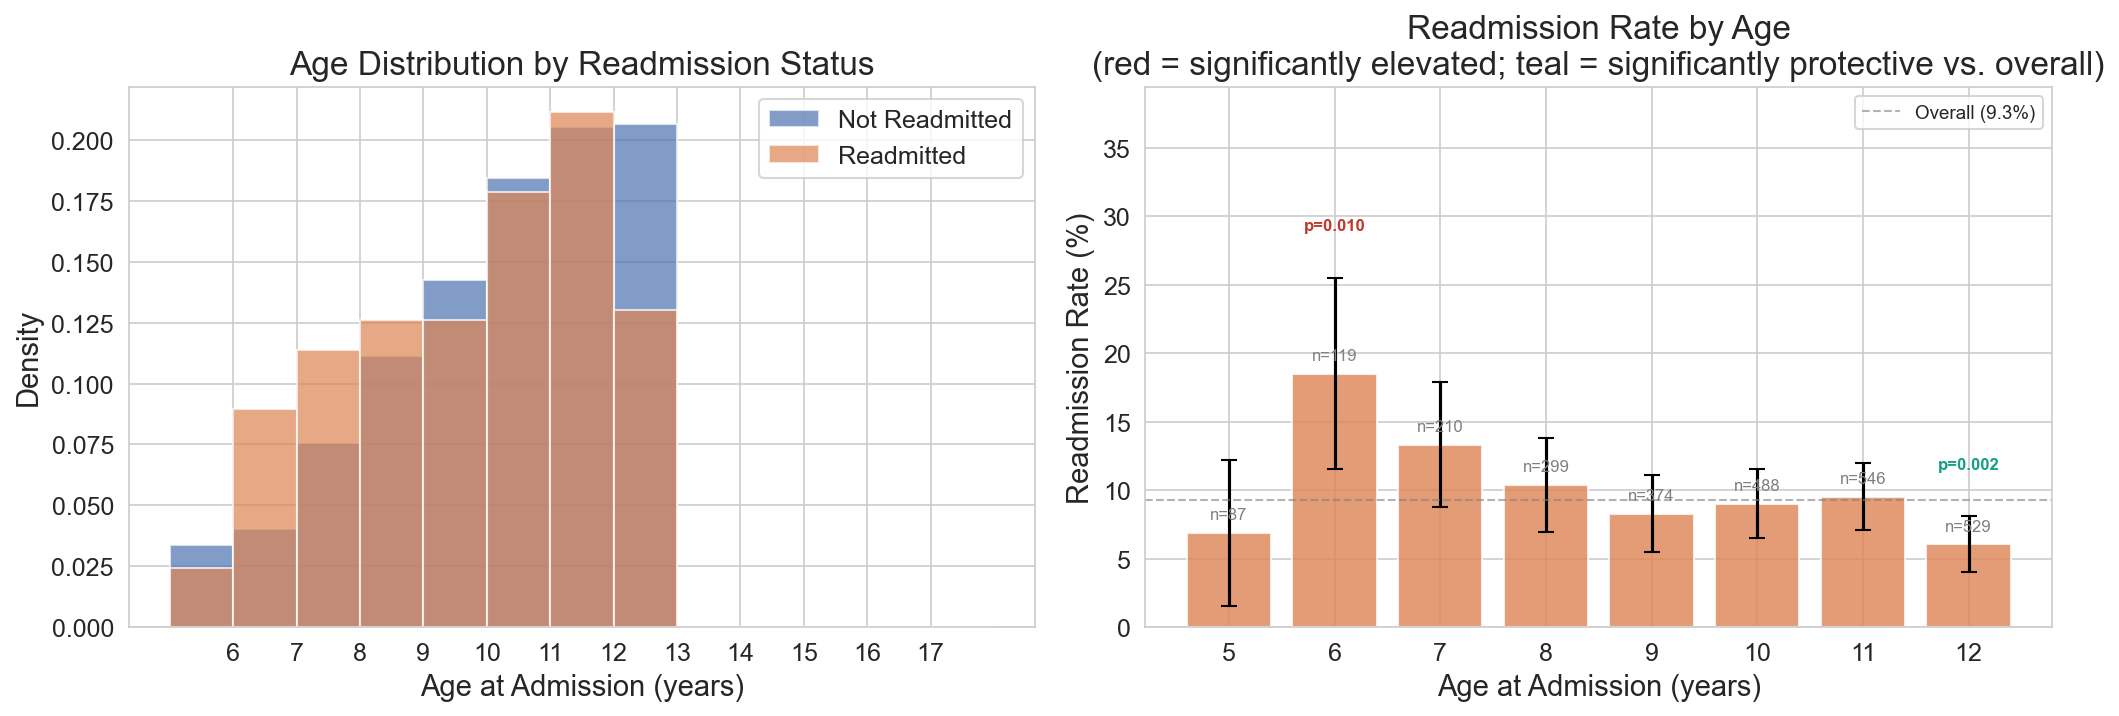

✓ Fig 1 saved

Protective age groups (rate < overall 9.3%, p<0.05):
  Age 12: 6.0% readmission rate — p=0.002

Elevated-risk age groups (rate > overall 9.3%, p<0.05):
  Age 6: 18.5% readmission rate — p=0.010


In [8]:

# ── Fig 1: Age distribution + readmission rate by age ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for status, color, label in [(0, BLUE, 'Not Readmitted'), (1, ORANGE, 'Readmitted')]:
    subset = df[df['readmitted'] == status]['age'].dropna()
    axes[0].hist(subset, bins=range(5, 19), alpha=0.7, color=color, label=label,
                 edgecolor='white', density=True)
axes[0].set_xlabel('Age at Admission (years)')
axes[0].set_ylabel('Density')
axes[0].set_title('Age Distribution by Readmission Status')
axes[0].legend()
axes[0].set_xticks(range(6, 18))

age_ra = df.groupby('age')['readmitted'].agg(['mean', 'count']).reset_index()
age_ra.columns = ['age', 'rate', 'n']
age_ra = age_ra[age_ra['n'] >= 10].reset_index(drop=True)
from statsmodels.stats.proportion import proportions_ztest
ci = 1.96 * np.sqrt(age_ra['rate'] * (1 - age_ra['rate']) / age_ra['n'])
overall_rate = df['readmitted'].mean()

# Classify each age: elevated (red), protective (teal), or ns
sig_labels, sig_colors = [], []
for i, row in age_ra.iterrows():
    _, p = proportions_ztest(row['rate'] * row['n'], row['n'], value=overall_rate)
    if p < 0.05:
        if row['rate'] > overall_rate:
            sig_labels.append('p<0.001' if p < 0.001 else f'p={p:.3f}')
            sig_colors.append('#c0392b')   # red = elevated risk
        else:
            sig_labels.append('p<0.001' if p < 0.001 else f'p={p:.3f}')
            sig_colors.append('#16a085')   # teal = protective
    else:
        sig_labels.append('')
        sig_colors.append(None)

axes[1].bar(age_ra['age'], age_ra['rate'] * 100, color=ORANGE, alpha=0.8, edgecolor='white')
axes[1].errorbar(age_ra['age'], age_ra['rate'] * 100, yerr=ci * 100,
                 fmt='none', color='black', capsize=4, linewidth=1.5)
axes[1].axhline(overall_rate * 100, color='gray', linestyle='--', linewidth=1,
                alpha=0.6, label=f'Overall ({overall_rate:.1%})')

for i, row in age_ra.iterrows():
    bar_top = row['rate'] * 100
    ci_top  = ci.iloc[i] * 100
    axes[1].text(row['age'], bar_top + 1.0,
                 f"n={int(row['n'])}", ha='center', fontsize=8, color='gray')
    if sig_labels[i]:
        axes[1].text(row['age'], bar_top + ci_top + 3.5,
                     sig_labels[i], color=sig_colors[i],
                     ha='center', fontsize=8, fontweight='bold')

max_top = (age_ra['rate'] * 100 + ci * 100).max()
axes[1].set_ylim(0, max_top * 1.55)
axes[1].set_xlabel('Age at Admission (years)')
axes[1].set_ylabel('Readmission Rate (%)')
axes[1].set_title('Readmission Rate by Age\n(red = significantly elevated; teal = significantly protective vs. overall)')
axes[1].set_xticks(age_ra['age'].astype(int))
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('figures/Fig1_age_distribution.png')
plt.show()
print("✓ Fig 1 saved")
print(f"\nProtective age groups (rate < overall {overall_rate:.1%}, p<0.05):")
for i, row in age_ra.iterrows():
    if sig_colors[i] == '#16a085':
        print(f"  Age {int(row['age'])}: {row['rate']:.1%} readmission rate — {sig_labels[i]}")
print(f"\nElevated-risk age groups (rate > overall {overall_rate:.1%}, p<0.05):")
for i, row in age_ra.iterrows():
    if sig_colors[i] == '#c0392b':
        print(f"  Age {int(row['age'])}: {row['rate']:.1%} readmission rate — {sig_labels[i]}")


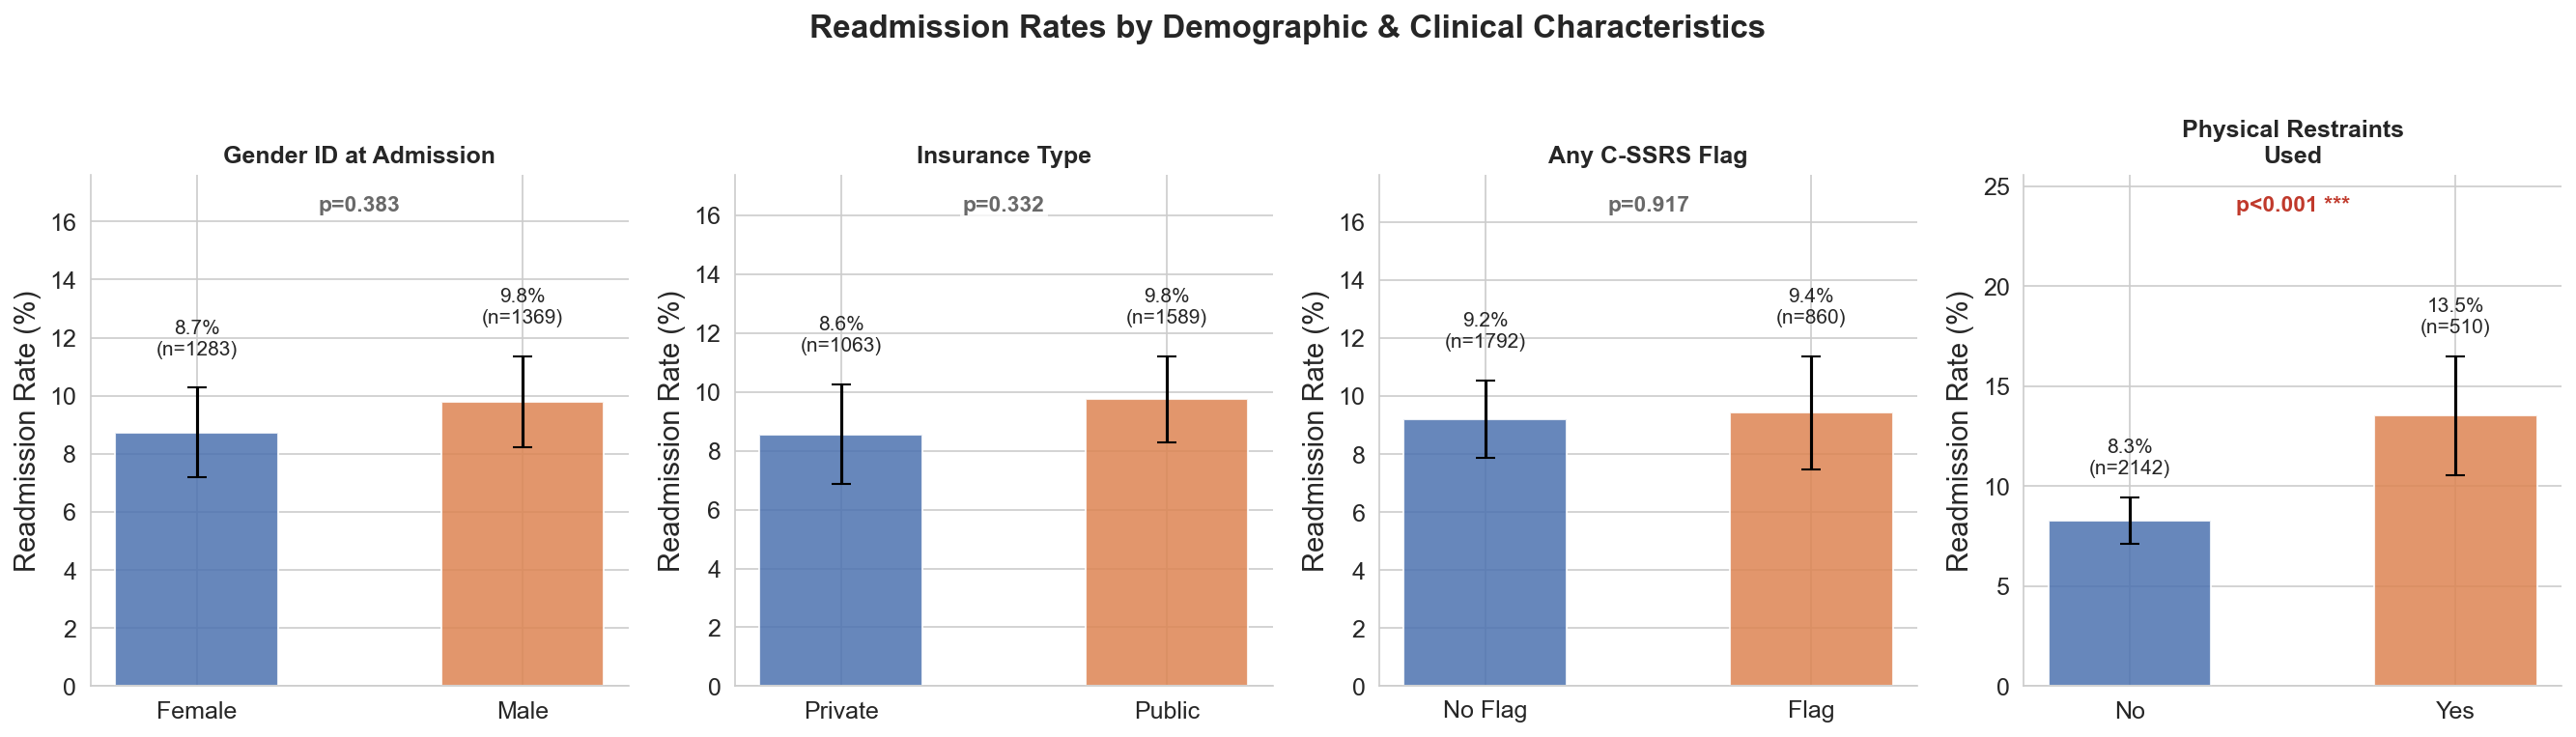

✓ Fig 2 saved


In [9]:

# ── Fig 2: Demographics panel (gender, insurance, C-SSRS, restraints) ─────────
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

binary_vars = [
    ('gender_male',      'Gender ID at Admission',       ['Female', 'Male']),
    ('insurance_public', 'Insurance Type',               ['Private', 'Public']),
    ('csrss_any',        'Any C-SSRS Flag',              ['No Flag', 'Flag']),
    ('had_restraints',   'Physical Restraints\nUsed',    ['No', 'Yes']),
]

for ax, (col, title, xlabels) in zip(axes, binary_vars):
    res  = df.groupby(col)['readmitted'].agg(['mean', 'count'])
    rates = res['mean'] * 100
    ns    = res['count']
    err   = 1.96 * np.sqrt(res['mean'] * (1 - res['mean']) / ns) * 100

    from scipy.stats import chi2_contingency
    tab = pd.crosstab(df[col], df['readmitted'])
    _, p, _, _ = chi2_contingency(tab)
    p_str = f'p={p:.3f}' if p >= 0.001 else 'p<0.001'
    if col == 'had_restraints' and p < 0.001:
        p_str += ' ***'
    p_color = '#c0392b' if p < 0.05 else 'dimgray'

    colors = [BLUE, ORANGE]
    bars = ax.bar(xlabels, rates.values, yerr=err.values, capsize=5,
                  color=colors, alpha=0.85, edgecolor='white', width=0.5)

    # Place label ABOVE the CI cap (rate + err + gap)
    for bar, n, rate, e in zip(bars, ns.values, rates.values, err.values):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + e + 1.0,
                f'{rate:.1f}%\n(n={n})', ha='center', va='bottom', fontsize=10)

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.text(0.5, 0.96, p_str, transform=ax.transAxes,
            ha='center', va='top', fontsize=11, fontweight='bold', color=p_color,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.75, pad=1.5))
    ax.set_ylabel('Readmission Rate (%)')
    ax.set_ylim(0, (rates.values + err.values).max() * 1.55)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Readmission Rates by Demographic & Clinical Characteristics',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/Fig2_demographics_panel.png')
plt.show()
print("✓ Fig 2 saved")

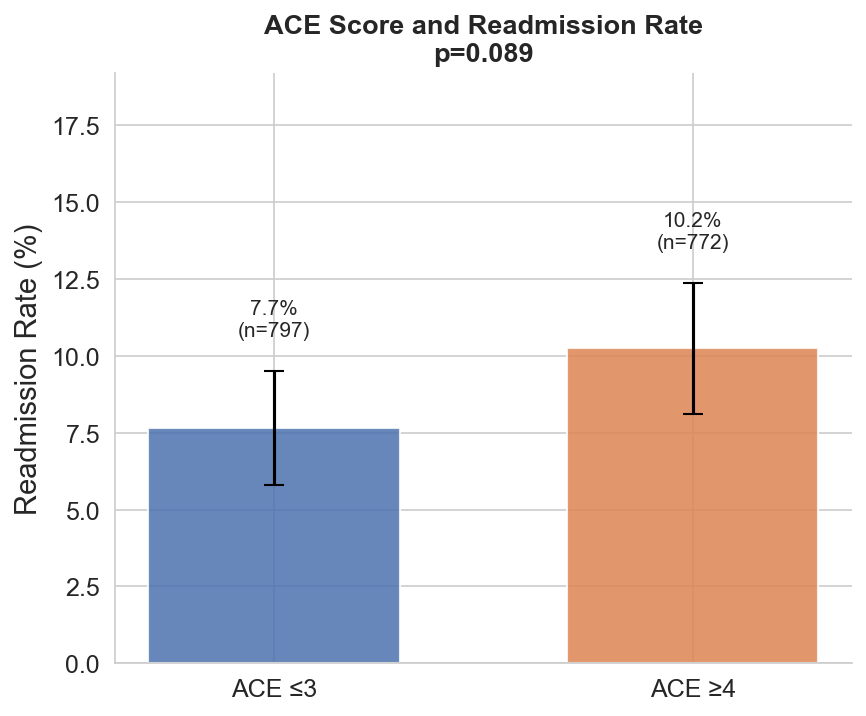

✓ Fig 2b saved


In [10]:

# ── Fig 2b: Readmission rate by ACE score (≤3 vs ≥4) ──────────────────────────
ace_df = df[df['ace_score'].notna()].copy()
ace_df['ace_group'] = np.where(ace_df['ace_score'] >= 4, 'ACE ≥4', 'ACE ≤3')
res = ace_df.groupby('ace_group')['readmitted'].agg(['mean', 'count'])
res = res.reindex(['ACE ≤3', 'ACE ≥4'])
rates = res['mean'] * 100
ns = res['count']
err = 1.96 * np.sqrt(res['mean'] * (1 - res['mean']) / ns) * 100

from scipy.stats import chi2_contingency
tab = pd.crosstab(ace_df['ace_group'], ace_df['readmitted'])
_, p, _, _ = chi2_contingency(tab)
p_str = f'p={p:.3f}' if p >= 0.001 else 'p<0.001'

fig, ax = plt.subplots(figsize=(6, 5))
colors = [BLUE, ORANGE]
bars = ax.bar(res.index, rates.values, yerr=err.values, capsize=5,
              color=colors, alpha=0.85, edgecolor='white', width=0.6)

for bar, n, rate, e in zip(bars, ns.values, rates.values, err.values):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + e + 1.0,
            f'{rate:.1f}%\n(n={n})', ha='center', va='bottom', fontsize=10)

ax.set_title(f'ACE Score and Readmission Rate\n{p_str}', fontsize=13, fontweight='bold')
ax.set_ylabel('Readmission Rate (%)')
ax.set_ylim(0, (rates.values + err.values).max() * 1.55)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/Fig2b_ace_readmission.png')
plt.show()
print("✓ Fig 2b saved")


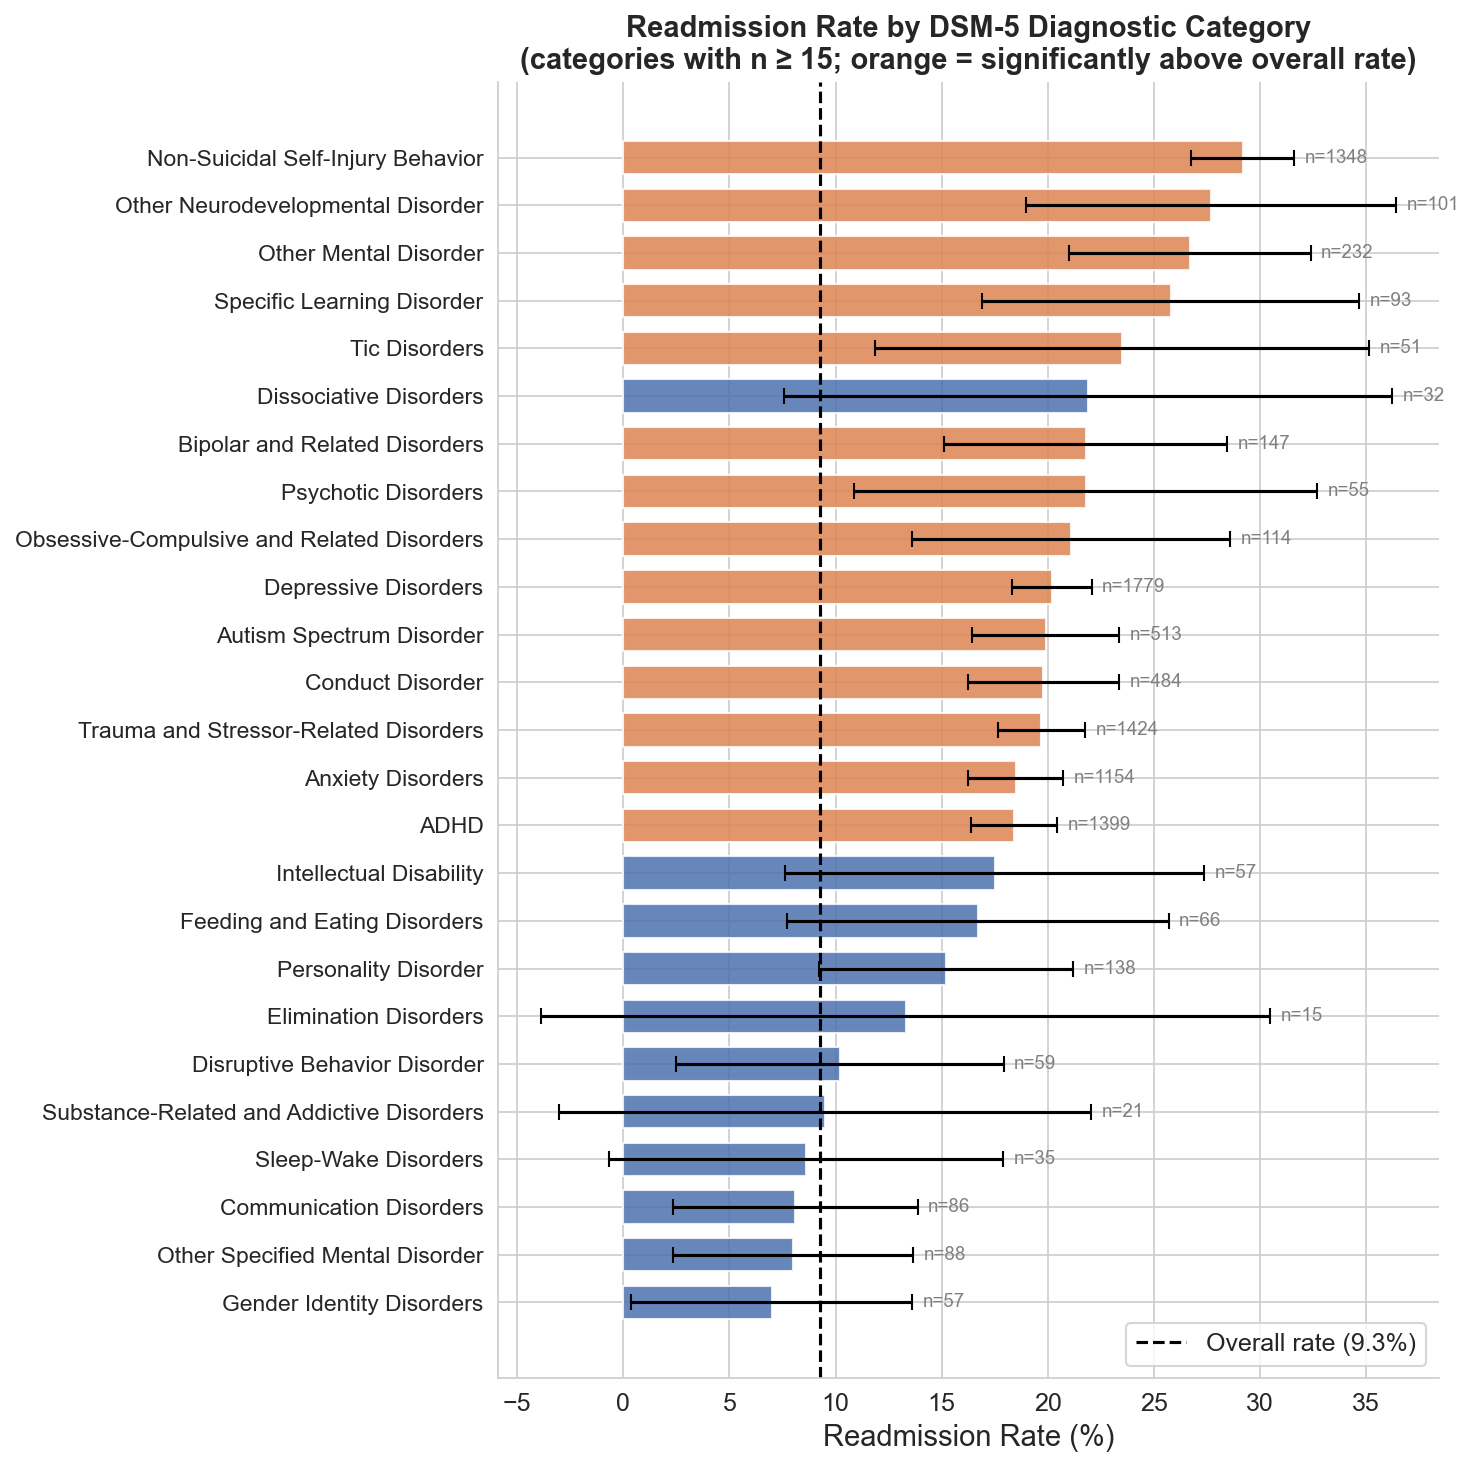

✓ Fig 3 saved


In [11]:

# ── Fig 3: Readmission rate by DSM-5 category (horizontal dot plot) ────────────
dsm5_long = pd.read_csv('DSM5_Readmission_Analysis.csv')
dsm5_long.columns = ['category', 'readmit_n', 'total_n', 'rate']
dsm5_long = dsm5_long.dropna(subset=['rate'])
dsm5_long = dsm5_long[dsm5_long['total_n'] >= 15]
dsm5_long = dsm5_long.sort_values('rate', ascending=True).reset_index(drop=True)

overall_rate = df['readmitted'].mean() * 100

# Confidence intervals
dsm5_long['p'] = dsm5_long['rate'] / 100
dsm5_long['ci'] = 1.96 * np.sqrt(dsm5_long['p'] * (1 - dsm5_long['p']) / dsm5_long['total_n']) * 100

# Orange only if lower CI bound strictly exceeds overall rate (significantly elevated)
dsm5_long['color'] = [
    ORANGE if (row['rate'] - row['ci']) > overall_rate else BLUE
    for _, row in dsm5_long.iterrows()
]

fig, ax = plt.subplots(figsize=(10, 10))
y_pos = range(len(dsm5_long))

ax.barh(y_pos, dsm5_long['rate'], xerr=dsm5_long['ci'], color=dsm5_long['color'],
        alpha=0.85, edgecolor='white', height=0.7,
        error_kw={'capsize': 4, 'linewidth': 1.5, 'ecolor': 'black'})

ax.set_yticks(y_pos)
ax.set_yticklabels(dsm5_long['category'], fontsize=11)
ax.axvline(overall_rate, color='black', linestyle='--',
           linewidth=1.5, label=f"Overall rate ({overall_rate:.1f}%)")

for i, (_, row) in enumerate(dsm5_long.iterrows()):
    ax.text(row['rate'] + row['ci'] + 0.5, i, f"n={int(row['total_n'])}",
            va='center', fontsize=9, color='gray')

ax.set_xlabel('Readmission Rate (%)')
ax.set_title('Readmission Rate by DSM-5 Diagnostic Category\n(categories with n ≥ 15; orange = significantly above overall rate)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/Fig3_readmission_by_dsm5.png')
plt.show()
print("✓ Fig 3 saved")


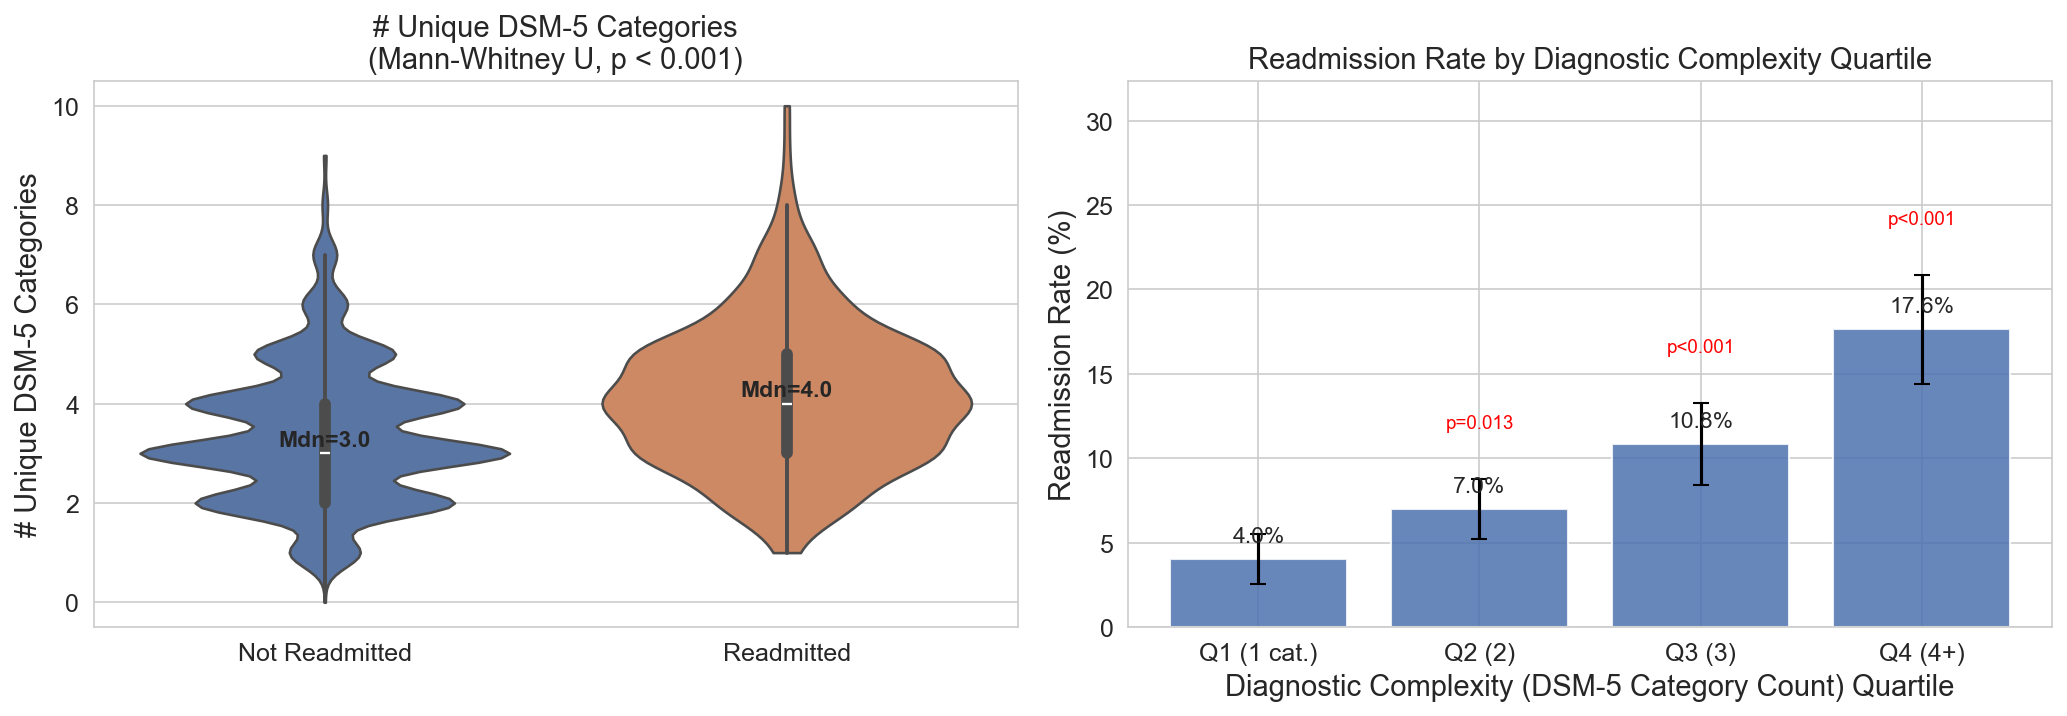

✓ Fig 4 saved


In [12]:

# ── Fig 4: Diagnostic complexity (# DSM-5 categories) by readmission ──────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: violin plot of DSM-5 category count
plot_df = df[['n_dsm5_categories', 'readmitted']].copy()
plot_df['Status'] = plot_df['readmitted'].map({0: 'Not Readmitted', 1: 'Readmitted'})

sns.violinplot(data=plot_df, x='Status', y='n_dsm5_categories',
               palette=PALETTE, inner='box', ax=axes[0], cut=0)
for i, (status, color) in enumerate([(0, BLUE), (1, ORANGE)]):
    med = df[df['readmitted'] == status]['n_dsm5_categories'].median()
    axes[0].text(i, med + 0.15, f'Mdn={med:.1f}', ha='center', fontsize=11, fontweight='bold')

u, p = stats.mannwhitneyu(
    df[df['readmitted']==1]['n_dsm5_categories'],
    df[df['readmitted']==0]['n_dsm5_categories'],
    alternative='two-sided'
)
p_str = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
axes[0].set_title(f'# Unique DSM-5 Categories\n(Mann-Whitney U, {p_str})', fontsize=14)
axes[0].set_xlabel('')
axes[0].set_ylabel('# Unique DSM-5 Categories')

# Right: readmission rate by complexity quartile
df['complexity_q'] = pd.qcut(df['n_dsm5_categories'], q=4,
                              labels=['Q1 (1 cat.)', 'Q2 (2)', 'Q3 (3)', 'Q4 (4+)'],
                              duplicates='drop')
q_rate = df.groupby('complexity_q', observed=True)['readmitted'].agg(['mean', 'count']).reset_index()
q_rate.columns = ['quartile', 'rate', 'n']
ci = 1.96 * np.sqrt(q_rate['rate'] * (1 - q_rate['rate']) / q_rate['n'])

bars = axes[1].bar(q_rate['quartile'], q_rate['rate'] * 100,
                   color=BLUE, alpha=0.85, edgecolor='white')
axes[1].errorbar(q_rate['quartile'], q_rate['rate'] * 100, yerr=ci * 100,
                 fmt='none', color='black', capsize=4, linewidth=1.5)

from statsmodels.stats.proportion import proportions_ztest
q1_rate = q_rate.iloc[0]['rate']
q1_n    = int(q_rate.iloc[0]['n'])

# Compute max top for ylim before annotating
max_top = max(q_rate['rate'].values * 100 + ci.values * 100)
axes[1].set_ylim(0, max_top * 1.55)

for idx, (bar, row_data) in enumerate(zip(bars, q_rate.itertuples())):
    rate_pct = row_data.rate * 100
    ci_pct   = ci.iloc[idx] * 100
    axes[1].text(bar.get_x() + bar.get_width()/2, rate_pct + 1,
                 f"{rate_pct:.1f}%", ha='center', fontsize=11)
    if idx > 0:
        _, p_q = proportions_ztest(
            [int(round(row_data.rate * row_data.n)), int(round(q1_rate * q1_n))],
            [int(row_data.n), q1_n]
        )
        p_label = 'p<0.001' if p_q < 0.001 else f'p={p_q:.3f}'
        color = 'red' if p_q < 0.05 else 'gray'
        axes[1].text(bar.get_x() + bar.get_width()/2,
                     rate_pct + ci_pct + 3,
                     p_label, ha='center', fontsize=9, color=color)

axes[1].set_xlabel('Diagnostic Complexity (DSM-5 Category Count) Quartile')
axes[1].set_ylabel('Readmission Rate (%)')
axes[1].set_title('Readmission Rate by Diagnostic Complexity Quartile', fontsize=14)

plt.tight_layout()
plt.savefig('figures/Fig4_diagnostic_complexity.png')
plt.show()
print("✓ Fig 4 saved")


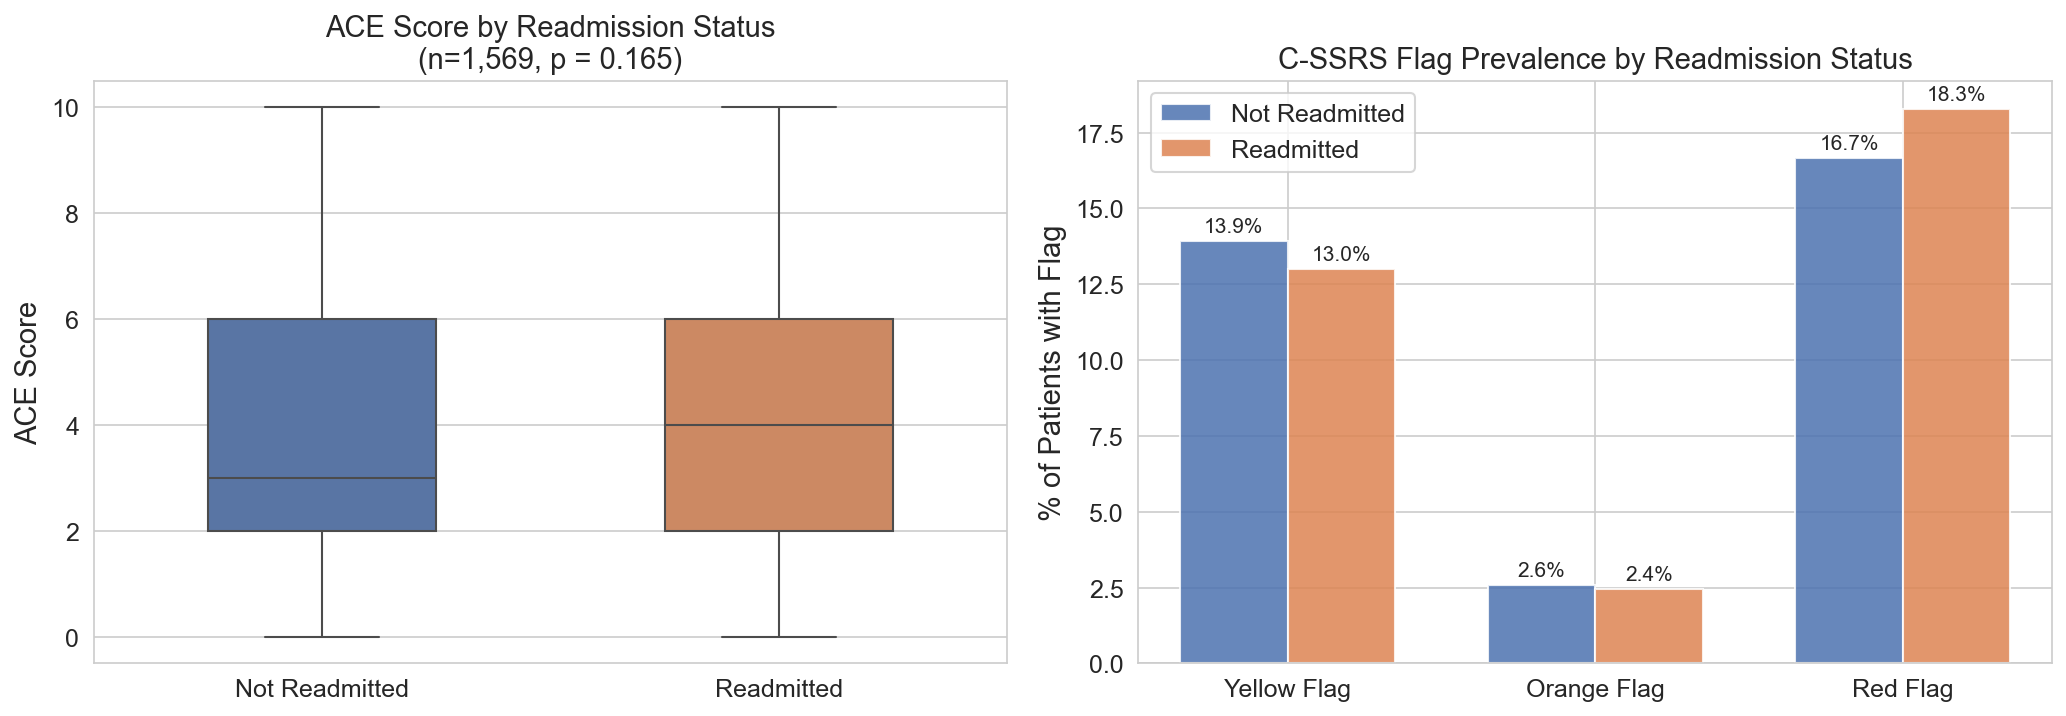

✓ Fig 5 saved


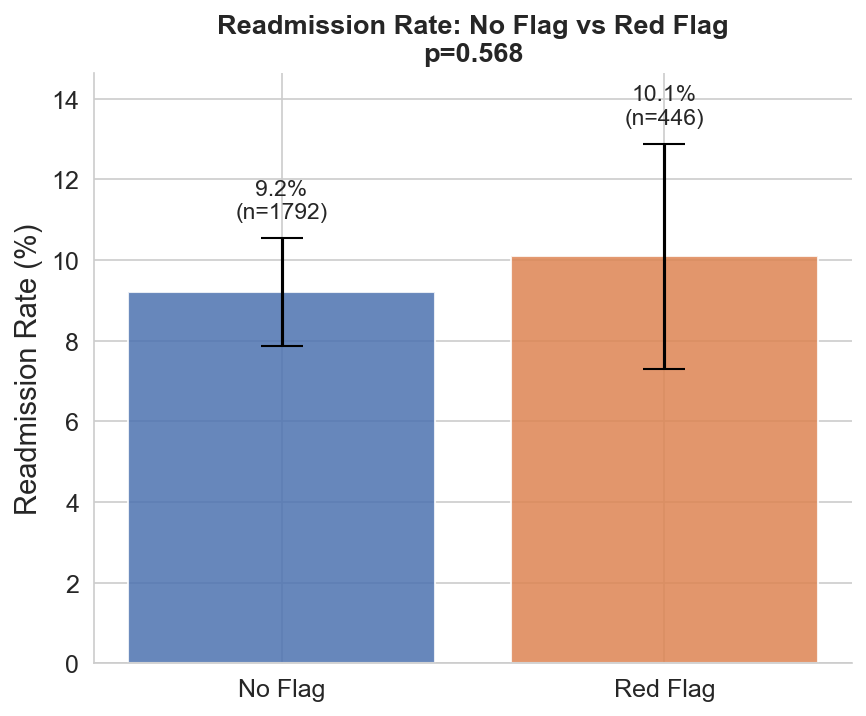

✓ Fig 5b saved


In [13]:

# ── Fig 5: ACE score + C-SSRS flags detail ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: ACE score by readmission (boxplot, only where measured)
ace_df = df[df['ace_score'].notna()][['ace_score', 'readmitted']].copy()
ace_df['Status'] = ace_df['readmitted'].map({0: 'Not Readmitted', 1: 'Readmitted'})
sns.boxplot(data=ace_df, x='Status', y='ace_score', palette=PALETTE,
            width=0.5, flierprops={'marker': 'o', 'alpha': 0.4}, ax=axes[0])
u, p = stats.mannwhitneyu(ace_df[ace_df['readmitted']==1]['ace_score'],
                           ace_df[ace_df['readmitted']==0]['ace_score'],
                           alternative='two-sided')
p_str = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
axes[0].set_title(f'ACE Score by Readmission Status\n(n={len(ace_df):,}, {p_str})', fontsize=14)
axes[0].set_xlabel('')
axes[0].set_ylabel('ACE Score')

# Right: C-SSRS flag levels
flag_cols   = ['csrss_yellow', 'csrss_orange', 'csrss_red']
flag_labels = ['Yellow Flag', 'Orange Flag', 'Red Flag']
x = np.arange(len(flag_cols))
width = 0.35

ra_rates  = [ra[c].mean() * 100 for c in flag_cols]
nra_rates = [nra[c].mean() * 100 for c in flag_cols]

b1 = axes[1].bar(x - width/2, nra_rates, width, color=BLUE,   alpha=0.85, label='Not Readmitted', edgecolor='white')
b2 = axes[1].bar(x + width/2, ra_rates,  width, color=ORANGE, alpha=0.85, label='Readmitted', edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(flag_labels)
axes[1].set_ylabel('% of Patients with Flag')
axes[1].set_title('C-SSRS Flag Prevalence by Readmission Status', fontsize=14)
axes[1].legend()
for bar, val in zip(list(b1) + list(b2), nra_rates + ra_rates):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.3,
                 f'{val:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('figures/Fig5_ace_csrss.png')
plt.show()
print("✓ Fig 5 saved")

# Specific comparison: No flag vs Red Flag
from statsmodels.stats.proportion import proportions_ztest
no_flag_r  = df[df['csrss_any']==0]['readmitted'].mean() * 100
red_flag_r = df[df['csrss_red']==1]['readmitted'].mean() * 100
ns_5    = [len(df[df['csrss_any']==0]), len(df[df['csrss_red']==1])]
rates_5 = [no_flag_r, red_flag_r]
errs_5  = [1.96 * np.sqrt((r/100)*(1-r/100)/n)*100 for r, n in zip(rates_5, ns_5)]
count_5 = [df[df['csrss_any']==0]['readmitted'].sum(), df[df['csrss_red']==1]['readmitted'].sum()]
_, p_5  = proportions_ztest(count_5, ns_5)
p_label_5 = 'p<0.001' if p_5 < 0.001 else f'p={p_5:.3f}'

fig_comp, ax_comp = plt.subplots(figsize=(6, 5))
ax_comp.bar(['No Flag', 'Red Flag'], rates_5, yerr=errs_5, color=[BLUE, ORANGE], capsize=10,
            alpha=0.85, edgecolor='white')
for i, (rate, n) in enumerate(zip(rates_5, ns_5)):
    ax_comp.text(i, rate + errs_5[i] + 0.5, f'{rate:.1f}%\n(n={n})', ha='center', fontsize=11)
ax_comp.set_ylabel('Readmission Rate (%)')
ax_comp.set_title(f'Readmission Rate: No Flag vs Red Flag\n{p_label_5}', fontsize=13, fontweight='bold')
ax_comp.set_ylim(0, max(rates_5) * 1.45)
ax_comp.spines['top'].set_visible(False)
ax_comp.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/Fig5b_no_flag_vs_red_flag.png')
plt.show()
print("✓ Fig 5b saved")


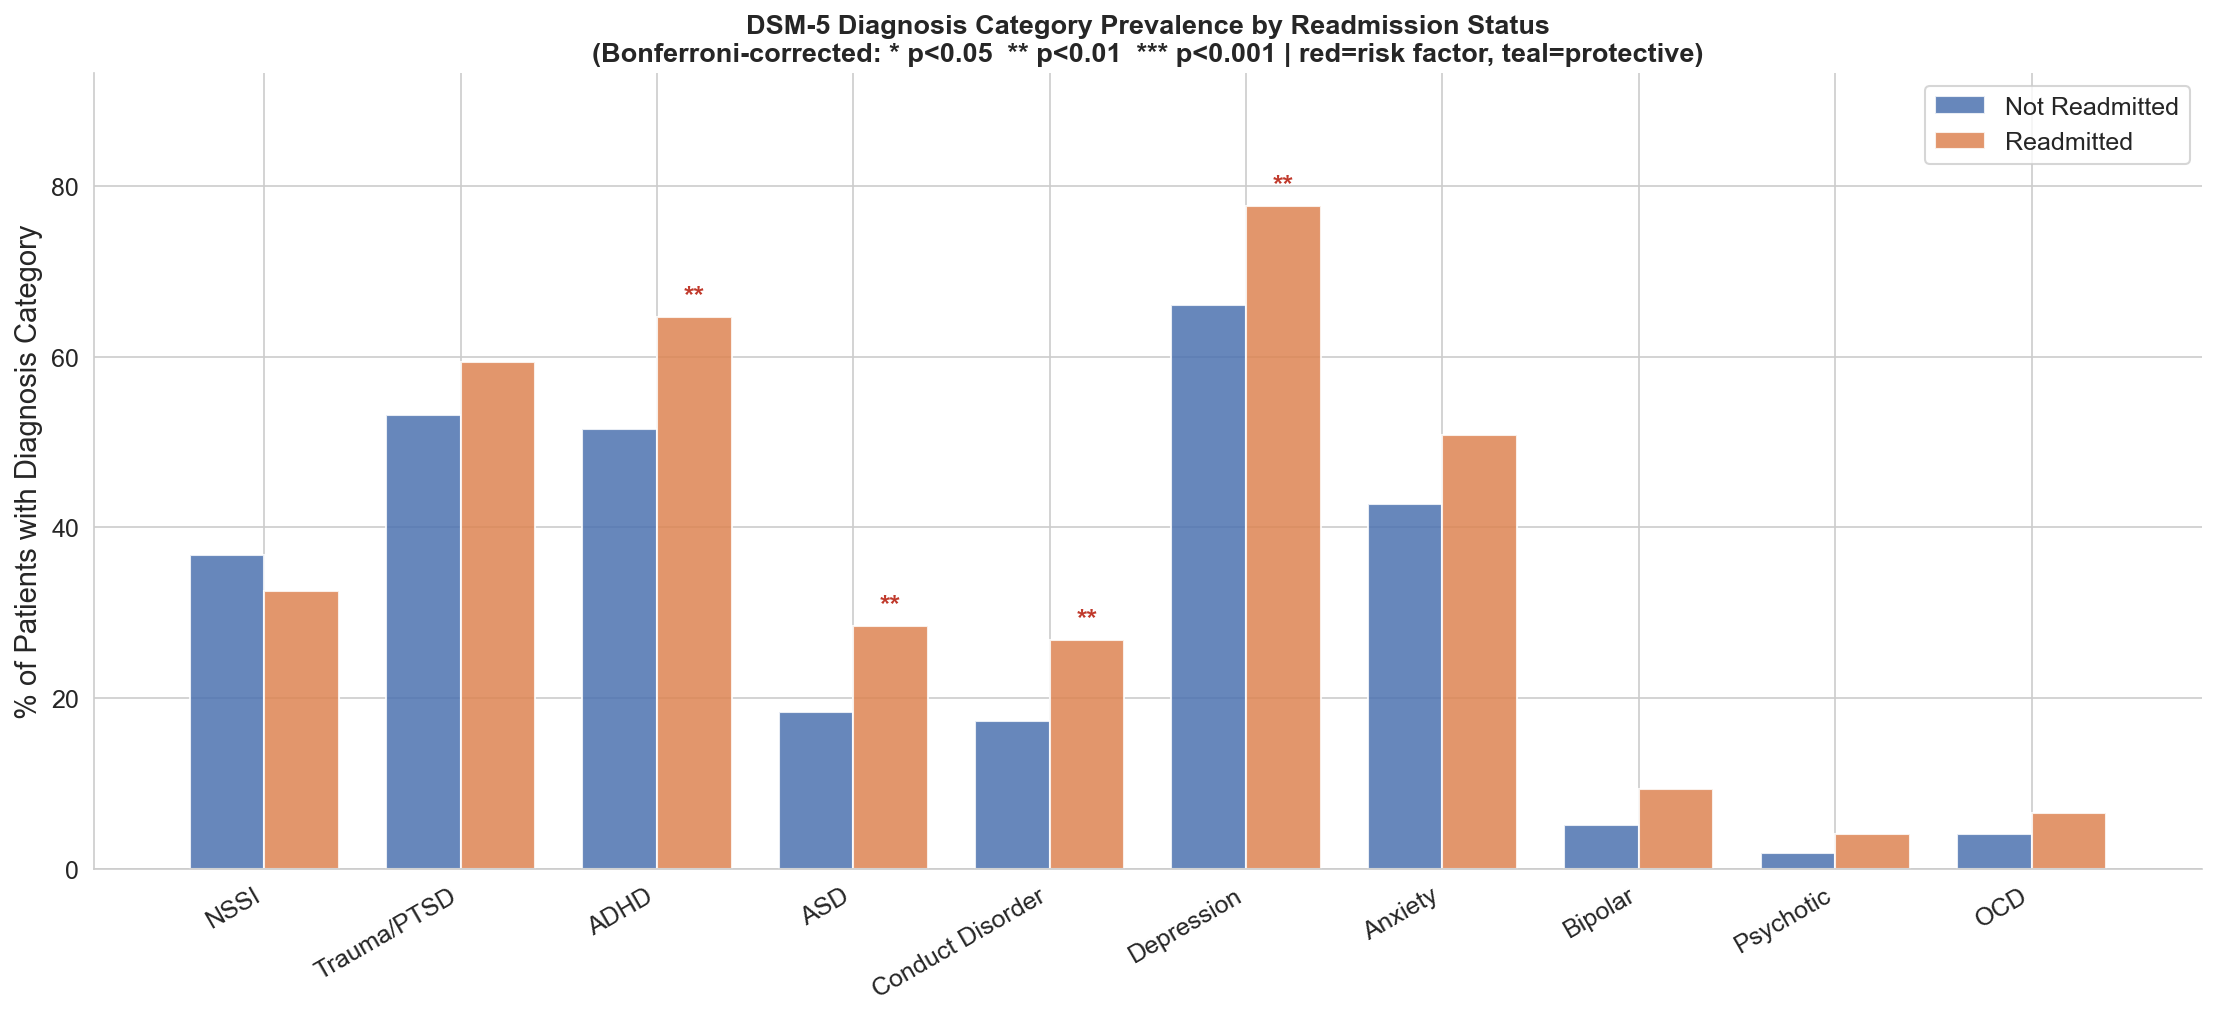

✓ Fig 6 saved

Significance summary (Bonferroni-corrected):
  ADHD                 **  (risk)
  ASD                  **  (risk)
  Conduct Disorder     **  (risk)
  Depression           **  (risk)


In [14]:

# ── Fig 6: DSM-5 diagnosis prevalence grouped bar + chi-squared significance ──
from scipy.stats import chi2_contingency

diag_flags = {
    'NSSI':             'has_nssi',
    'Trauma/PTSD':      'has_trauma',
    'ADHD':             'has_adhd',
    'ASD':              'has_asd',
    'Conduct Disorder': 'has_conduct',
    'Depression':       'has_depression',
    'Anxiety':          'has_anxiety',
    'Bipolar':          'has_bipolar',
    'Psychotic':        'has_psychotic',
    'OCD':              'has_ocd',
}
labels = list(diag_flags.keys())
cols   = list(diag_flags.values())

nra_pct = [nra[c].mean() * 100 for c in cols]
ra_pct  = [ra[c].mean() * 100  for c in cols]

# Chi-squared with Bonferroni correction
n_tests = len(cols)
sig_markers, directions = [], []
for c, nr, r in zip(cols, nra_pct, ra_pct):
    tab = pd.crosstab(df['readmitted'], df[c])
    _, p, _, _ = chi2_contingency(tab)
    p_bonf = min(p * n_tests, 1.0)
    star = '***' if p_bonf < 0.001 else ('**' if p_bonf < 0.01 else ('*' if p_bonf < 0.05 else ''))
    sig_markers.append(star)
    directions.append('risk' if r > nr else 'protective')

x = np.arange(len(labels))
width = 0.38

fig, ax = plt.subplots(figsize=(15, 7))
b1 = ax.bar(x - width/2, nra_pct, width, color=BLUE,   alpha=0.85, label='Not Readmitted', edgecolor='white')
b2 = ax.bar(x + width/2, ra_pct,  width, color=ORANGE, alpha=0.85, label='Readmitted',     edgecolor='white')

# Significance markers above the taller bar; teal for protective, red for risk
for i, (sig, direction) in enumerate(zip(sig_markers, directions)):
    if not sig:
        continue
    top  = max(nra_pct[i], ra_pct[i])
    xpos = x[i] + (width/2 if ra_pct[i] >= nra_pct[i] else -width/2)
    color = '#c0392b' if direction == 'risk' else '#16a085'
    ax.text(xpos, top + 1.5, sig, ha='center', fontsize=13, color=color, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=12)
ax.set_ylabel('% of Patients with Diagnosis Category')
ax.set_ylim(0, max(max(nra_pct), max(ra_pct)) * 1.2)
ax.set_title('DSM-5 Diagnosis Category Prevalence by Readmission Status\n'
             '(Bonferroni-corrected: * p<0.05  ** p<0.01  *** p<0.001 | red=risk factor, teal=protective)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/Fig6_diagnosis_prevalence.png')
plt.show()
print("✓ Fig 6 saved")
print("\nSignificance summary (Bonferroni-corrected):")
for lbl, sig, d in zip(labels, sig_markers, directions):
    if sig:
        print(f"  {lbl:<20} {sig}  ({d})")


In [15]:
# ── Logistic regression: build feature matrix ─────────────────────────────────

FEATURES = {
    # Demographics
    'age':                   'Age at Admission',
    'gender_male':           'Male Sex',
    'insurance_public':      'Public Insurance (AHCCCS)',
    # Clinical
    'ace_score':             'ACE Score',
    'had_restraints':        'Physical Restraints',
    'csrss_any':             'Any C-SSRS Flag',
    'los_days':              'Length of Stay (days)',
    # Diagnostic complexity
    'n_dsm5_categories':     '# DSM-5 Categories',
    'has_medical_comorbidity': 'Medical Comorbidity',
    # Diagnosis category flags (using PyHealth CCSR mappings)
    'has_nssi':              'NSSI Diagnosis',
    'has_trauma':            'Trauma/PTSD',
    'has_adhd':              'ADHD',
    'has_asd':               'ASD',
    'has_conduct':           'Conduct Disorder',
    'has_depression':        'Depression',
    'has_anxiety':           'Anxiety',
    'has_bipolar':           'Bipolar Disorder',
    'has_psychotic':         'Psychotic Disorder',
}

feat_cols = list(FEATURES.keys())
model_df  = df[feat_cols + ['readmitted', 'csrss_red', 'csrss_orange', 'csrss_yellow', 'n_medical_chronic_pyhealth']].copy()

# MICE Imputation for missing ACE Score and LOS
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

imp_cols = ['age', 'ace_score', 'los_days']
imputer = IterativeImputer(estimator=RandomForestRegressor(n_estimators=50, random_state=42), max_iter=10, random_state=42)

model_df[imp_cols] = imputer.fit_transform(model_df[imp_cols])

# Handle any remaining missing values
model_df = model_df.dropna()

print(f"Model dataset: {len(model_df):,} patients | {model_df['readmitted'].sum()} readmitted ({model_df['readmitted'].mean():.1%})")
print(f"Features: {len(feat_cols)}")

Model dataset: 2,652 patients | 246 readmitted (9.3%)
Features: 18


Overall Readmission Stats (Continuous):
  Mean # Readmissions: 0.10 ± 0.34
  Readmitted (%):      9.3%

ACE Score Stats:
  Mean:   3.7 ± 2.6
  Median: 3.0
  N collected: 1569 (59.2%)

Length of Stay (LOS):
  Mean:   10.0 ± 6.9
  Median: 8.0

Diagnostic Burdens (Mean ± SD, Median):
  Visit                4.3 ± 2.3 | Mdn: 4.0
  Chronic              5.3 ± 5.4 | Mdn: 4.0
  Non-Suicidal (NSSI)  0.4 ± 0.5 | Mdn: 0.0

Medical Comorbidity Breakdown (Top Types; categories may overlap by patient):
               type   n Patient % Mention %
       GI/Digestive 240      9.0%     27.5%
  Metabolic/Obesity 217      8.2%     24.8%
     Sleep Disorder 180      6.8%     20.6%
Respiratory/Allergy 135      5.1%     15.4%
     Renal/Urologic 102      3.8%     11.7%


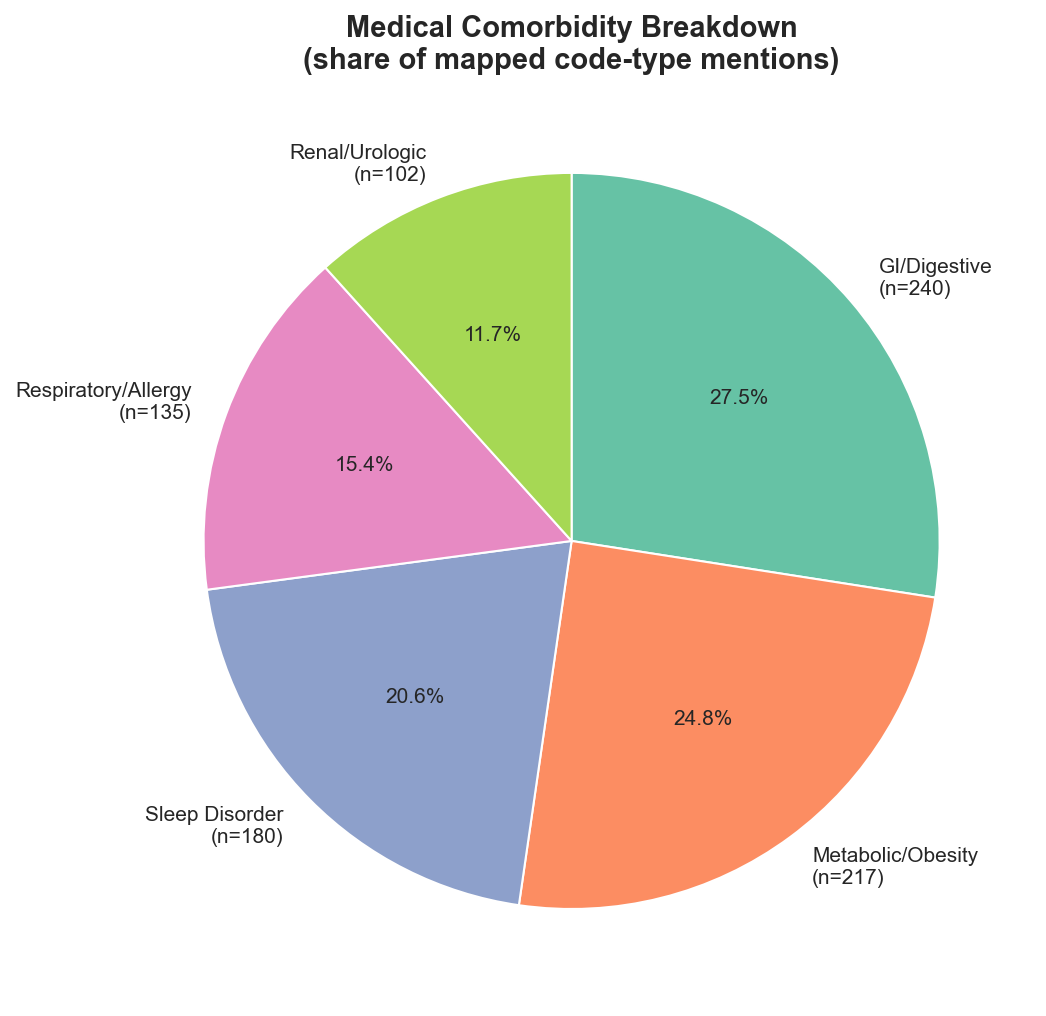


✓ Medical comorbidity breakdown saved


In [16]:

# ── Cohort Summary & Detailed Descriptive Statistics ──────────────────────────
# Continuous Readmissions
print(f"Overall Readmission Stats (Continuous):")
print(f"  Mean # Readmissions: {df['Readmissions'].mean():.2f} ± {df['Readmissions'].std():.2f}")
print(f"  Readmitted (%):      {df['readmitted'].mean():.1%}")

# ACE Score Detailed
ace_sub = df['ace_score'].dropna()
print(f"\nACE Score Stats:")
print(f"  Mean:   {ace_sub.mean():.1f} ± {ace_sub.std():.1f}")
print(f"  Median: {ace_sub.median():.1f}")
print(f"  N collected: {len(ace_sub)} ({len(ace_sub)/len(df):.1%})")

# LOS Detailed
print(f"\nLength of Stay (LOS):")
print(f"  Mean:   {df['los_days'].mean():.1f} ± {df['los_days'].std():.1f}")
print(f"  Median: {df['los_days'].median():.1f}")

# Diagnostic Counts
print(f"\nDiagnostic Burdens (Mean ± SD, Median):")
for col, label in [('n_visit_diags', 'Visit'), ('n_chronic_diags', 'Chronic'), ('has_nssi', 'Non-Suicidal (NSSI)')]:
    print(f"  {label:<20} {df[col].mean():.1f} ± {df[col].std():.1f} | Mdn: {df[col].median():.1f}")

# Medical Comorbidity Breakdown
all_m = [t for sublist in df['medical_comorbidity_types'] for t in sublist]
med_counts = pd.Series(all_m, name='Medical comorbidity type').value_counts()
med_breakdown = (
    med_counts.rename_axis('type')
    .reset_index(name='n')
    .assign(
        pct_of_patients=lambda x: 100 * x['n'] / len(df),
        pct_of_mentions=lambda x: 100 * x['n'] / x['n'].sum(),
    )
)
med_breakdown.to_csv('figures/Medical_Comorbidity_Breakdown.csv', index=False)

print(f"\nMedical Comorbidity Breakdown (Top Types; categories may overlap by patient):")
if med_breakdown.empty:
    print("  No mapped medical comorbidity categories found.")
else:
    display_breakdown = med_breakdown.copy()
    display_breakdown['Patient %'] = display_breakdown['pct_of_patients'].map(lambda x: f'{x:.1f}%')
    display_breakdown['Mention %'] = display_breakdown['pct_of_mentions'].map(lambda x: f'{x:.1f}%')
    print(display_breakdown[['type', 'n', 'Patient %', 'Mention %']].to_string(index=False))

    fig, ax = plt.subplots(figsize=(8, 7))
    labels = [f"{row.type}\n(n={int(row.n)})" for row in med_breakdown.itertuples()]
    colors_med = sns.color_palette('Set2', n_colors=len(med_breakdown))
    ax.pie(
        med_breakdown['n'],
        labels=labels,
        autopct='%1.1f%%',
        startangle=90,
        counterclock=False,
        colors=colors_med,
        textprops={'fontsize': 10},
        wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    )
    ax.set_title('Medical Comorbidity Breakdown\n(share of mapped code-type mentions)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('figures/Fig_medical_comorbidity_breakdown.png')
    plt.show()
    print("\n✓ Medical comorbidity breakdown saved")

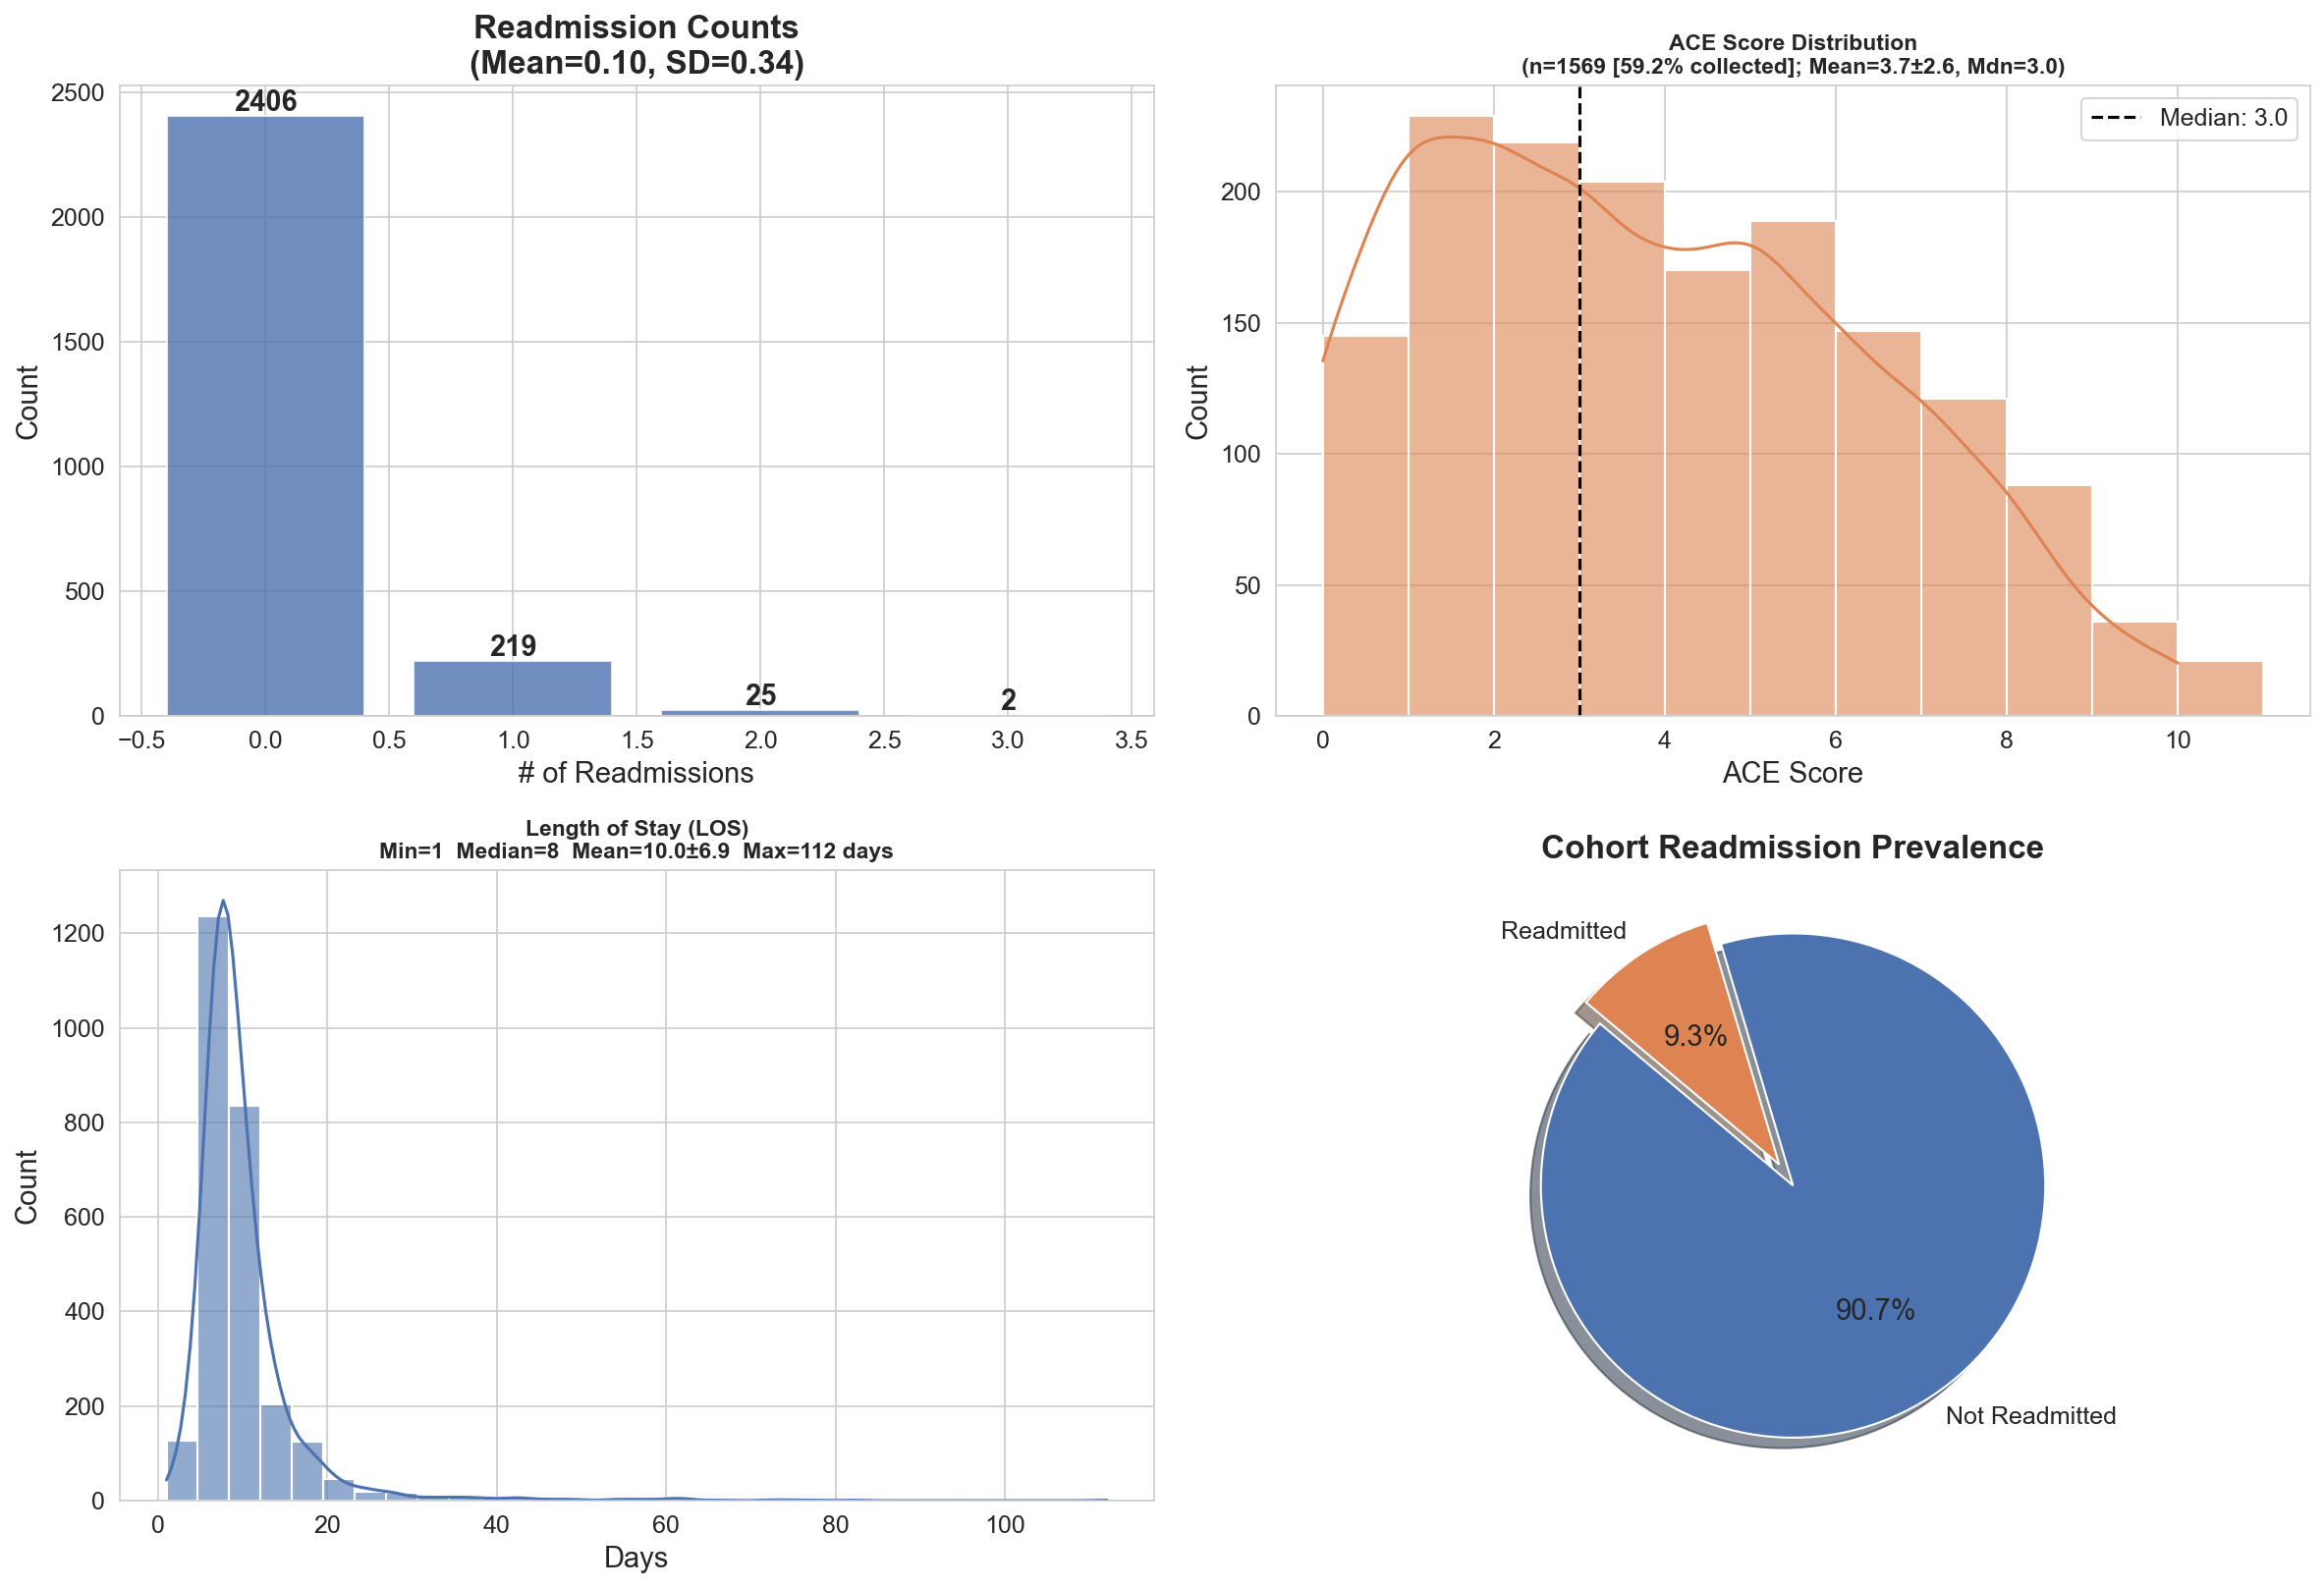

✓ Cohort visualizations saved


In [17]:

# ── Cohort Descriptive Visualizations ─────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Readmission Count Distribution
rc_counts = df['Readmissions'].fillna(0).value_counts().sort_index()
rc_mean = df['Readmissions'].fillna(0).mean()
rc_sd   = df['Readmissions'].fillna(0).std()
axes[0, 0].bar(rc_counts.index.astype(int), rc_counts.values, color=BLUE, alpha=0.8, edgecolor='white')
axes[0, 0].set_title(f"Readmission Counts\n(Mean={rc_mean:.2f}, SD={rc_sd:.2f})", fontweight='bold')
axes[0, 0].set_xlabel("# of Readmissions")
axes[0, 0].set_ylabel("Count")
for i, v in enumerate(rc_counts.values):
    axes[0, 0].text(rc_counts.index[i], v + 20, str(v), ha='center', fontweight='bold')

# 2. ACE Score Distribution
ace_sub = df['ace_score'].dropna()
sns.histplot(ace_sub, bins=range(0, 12), ax=axes[0, 1], color=ORANGE, kde=True, alpha=0.6)
axes[0, 1].set_title(
    f"ACE Score Distribution\n"
    f"(n={len(ace_sub)} [{100*len(ace_sub)/len(df):.1f}% collected]; "
    f"Mean={ace_sub.mean():.1f}±{ace_sub.std():.1f}, Mdn={ace_sub.median():.1f})",
    fontweight='bold', fontsize=11)
axes[0, 1].set_xlabel("ACE Score")
axes[0, 1].axvline(ace_sub.median(), color='black', linestyle='--', label=f'Median: {ace_sub.median():.1f}')
axes[0, 1].legend()

# 3. Length of Stay (LOS) Distribution  — with min, median, mean±SD, max
los = df['los_days'].dropna()
sns.histplot(los, bins=30, ax=axes[1, 0], color=BLUE, kde=True, alpha=0.6)
axes[1, 0].set_title(
    f"Length of Stay (LOS)\n"
    f"Min={los.min():.0f}  Median={los.median():.0f}  "
    f"Mean={los.mean():.1f}±{los.std():.1f}  Max={los.max():.0f} days",
    fontweight='bold', fontsize=11)
axes[1, 0].set_xlabel("Days")

# 4. Cohort Readmission Prevalence
ra_pct = df['readmitted'].mean() * 100
axes[1, 1].pie([100-ra_pct, ra_pct], labels=['Not Readmitted', 'Readmitted'],
               autopct='%1.1f%%', colors=[BLUE, ORANGE], startangle=140,
               explode=(0, 0.1), shadow=True)
axes[1, 1].set_title("Cohort Readmission Prevalence", fontweight='bold')

plt.tight_layout()
plt.savefig('figures/Cohort_Descriptive_Overview.png')
plt.show()
print("✓ Cohort visualizations saved")


In [18]:
# ── Logistic regression model + interaction terms ─────────────────────────────
# We test specific interactions hypothesized to be clinically relevant

# Keep a copy of unscaled for tree models
model_df_unscaled = model_df.copy()

# Standardize continuous variables for Odds Ratio interpretation and visible CIs
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scale_cols = ['age', 'los_days', 'ace_score', 'n_dsm5_categories']
model_df[scale_cols] = scaler.fit_transform(model_df[scale_cols])

interaction_labels = {
    'complexity_x_age': 'Age × Diagnostic Complexity',
    'ace_x_csrss':      'ACE Score × Any C-SSRS Flag',
    'medical_x_los':    'Medical Comorbidity × LOS',
}

model_df['complexity_x_age'] = model_df['n_dsm5_categories'] * model_df['age']
model_df['ace_x_csrss']      = model_df['ace_score'] * model_df['csrss_any']
model_df['medical_x_los']    = model_df['has_medical_comorbidity'] * model_df['los_days']
model_df_unscaled['complexity_x_age'] = model_df_unscaled['n_dsm5_categories'] * model_df_unscaled['age']
model_df_unscaled['ace_x_csrss']      = model_df_unscaled['ace_score'] * model_df_unscaled['csrss_any']
model_df_unscaled['medical_x_los']    = model_df_unscaled['has_medical_comorbidity'] * model_df_unscaled['los_days']

all_x_cols = feat_cols + list(interaction_labels.keys())

# Scale interactions
scaler_interactions = StandardScaler()
model_df[list(interaction_labels.keys())] = scaler_interactions.fit_transform(model_df[list(interaction_labels.keys())])


X = model_df[all_x_cols]
X = sm.add_constant(X)
y = model_df['readmitted']

logit_model = sm.Logit(y, X).fit(maxiter=200)
print(logit_model.summary2())

Optimization terminated successfully.
         Current function value: 0.286038
         Iterations 7
                            Results: Logit
Model:                Logit              Method:             MLE       
Dependent Variable:   readmitted         Pseudo R-squared:   0.074     
Date:                 2026-06-02 19:03   AIC:                1561.1454 
No. Observations:     2652               BIC:                1690.5729 
Df Model:             21                 Log-Likelihood:     -758.57   
Df Residuals:         2630               LL-Null:            -819.14   
Converged:            1.0000             LLR p-value:        4.4059e-16
No. Iterations:       7.0000             Scale:              1.0000    
-----------------------------------------------------------------------
                         Coef.  Std.Err.    z    P>|z|   [0.025  0.975]
-----------------------------------------------------------------------
const                   -3.7591   0.3927 -9.5717 0.0000 -4.5289

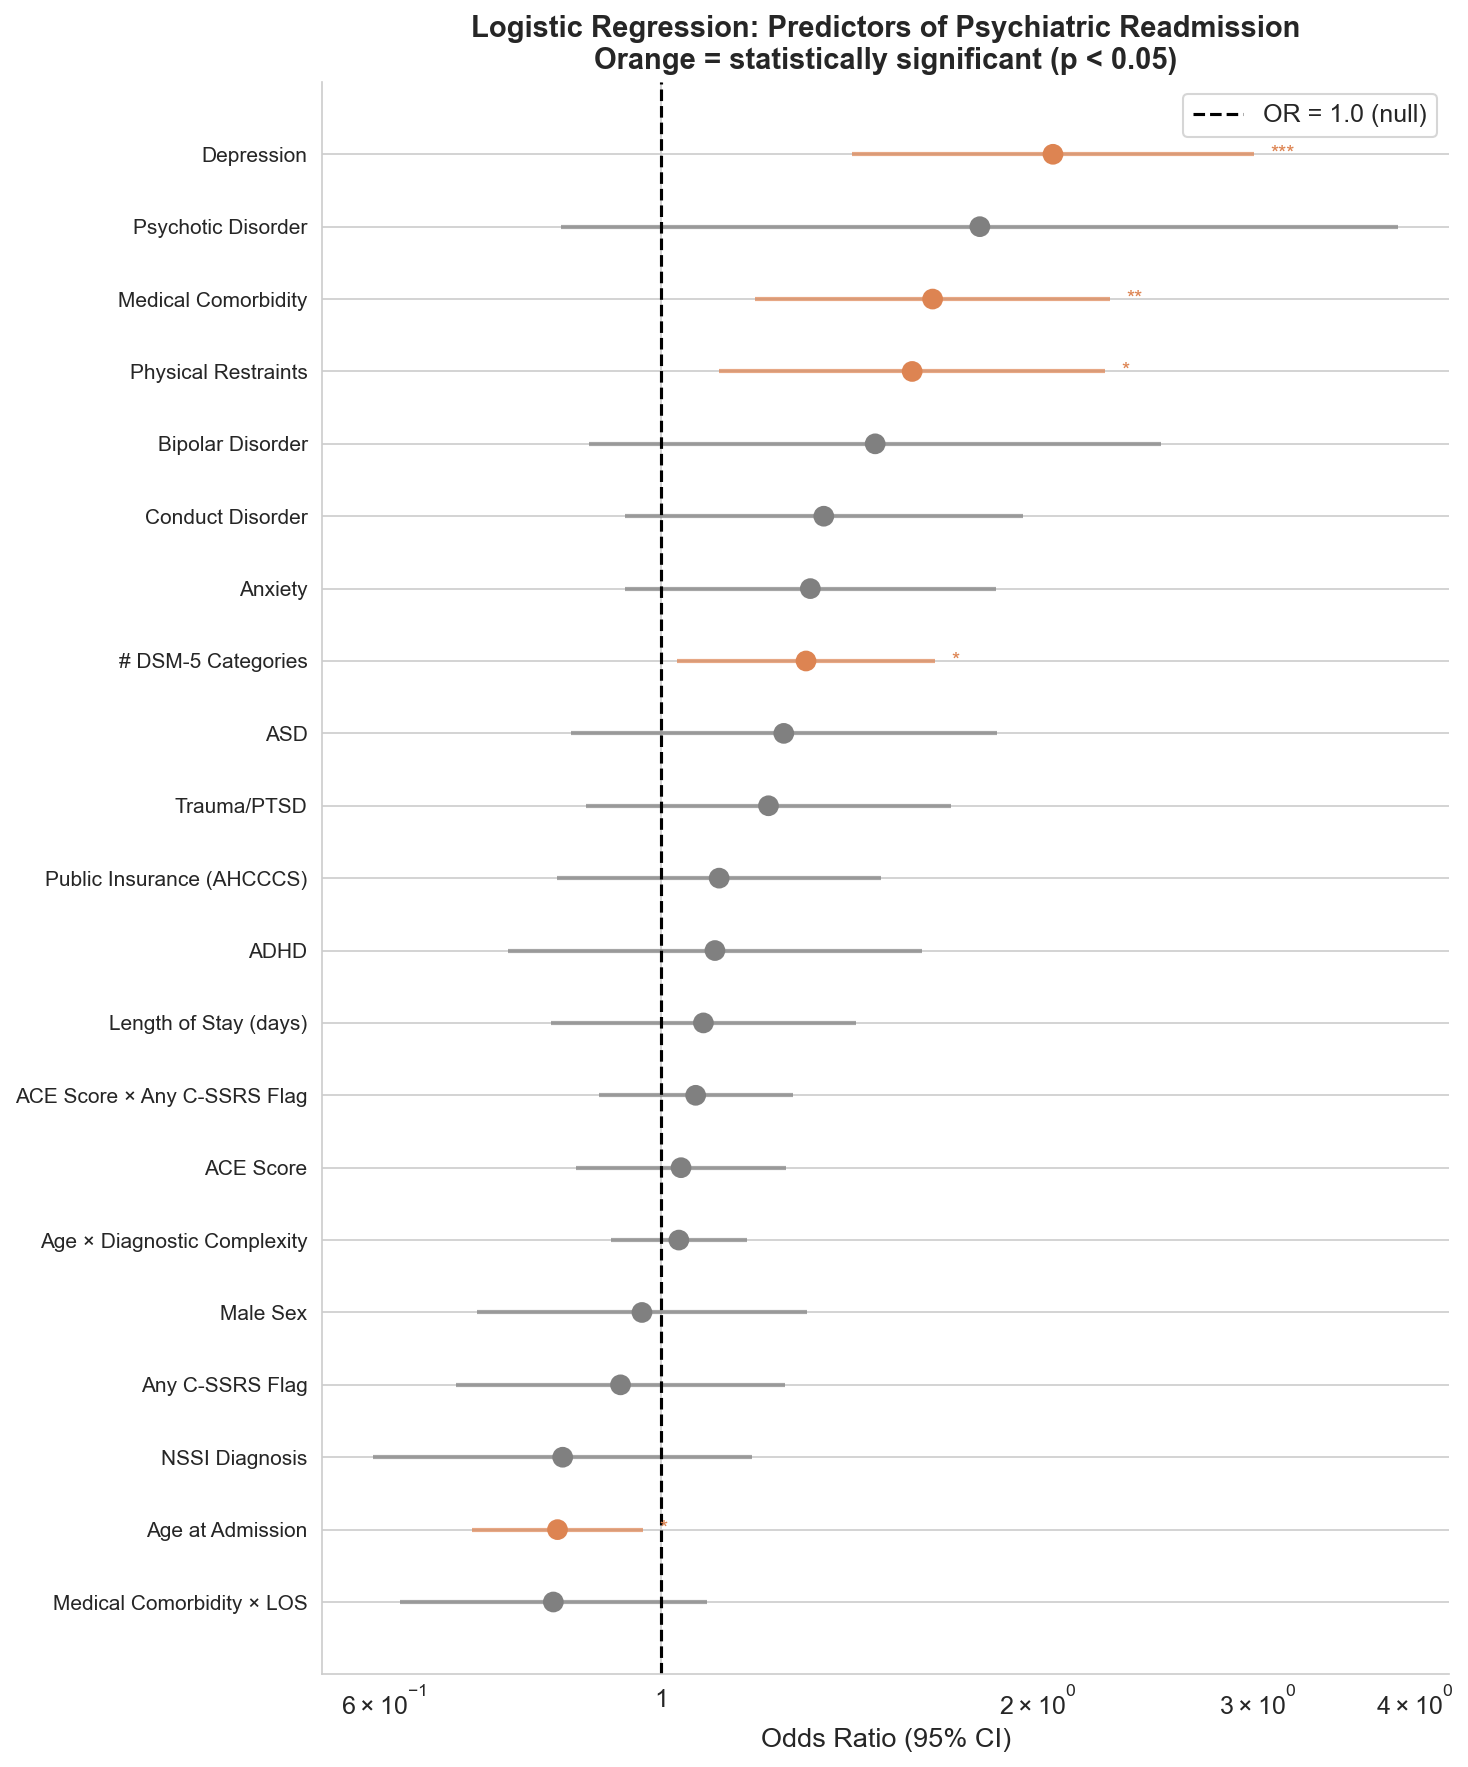

✓ Fig 7 saved


In [19]:

# ── Fig 7: Forest plot — odds ratios from logistic regression ─────────────────
all_labels = {**FEATURES, **interaction_labels}

coef_df = pd.DataFrame({
    'feature': logit_model.params.index,
    'coef':    logit_model.params.values,
    'se':      logit_model.bse.values,
    'pval':    logit_model.pvalues.values,
}).query("feature != 'const'")

coef_df['OR']    = np.exp(coef_df['coef'])
coef_df['OR_lo'] = np.exp(coef_df['coef'] - 1.96 * coef_df['se'])
coef_df['OR_hi'] = np.exp(coef_df['coef'] + 1.96 * coef_df['se'])
coef_df['label'] = coef_df['feature'].map(all_labels).fillna(coef_df['feature'])
coef_df['sig']   = coef_df['pval'] < 0.05
coef_df = coef_df.sort_values('OR', ascending=True)

fig, ax = plt.subplots(figsize=(10, 12))
y_pos = range(len(coef_df))
colors_lr = [ORANGE if s else 'gray' for s in coef_df['sig']]

ax.scatter(coef_df['OR'], y_pos, color=colors_lr, s=80, zorder=3)
ax.hlines(y_pos, coef_df['OR_lo'], coef_df['OR_hi'], 
          color=colors_lr, linewidth=2, alpha=0.7)
ax.axvline(1.0, color='black', linestyle='--', linewidth=1.5, label='OR = 1.0 (null)')
ax.set_yticks(y_pos)
ax.set_yticklabels(coef_df['label'], fontsize=10)
ax.set_xlabel('Odds Ratio (95% CI)', fontsize=13)
ax.set_title('Logistic Regression: Predictors of Psychiatric Readmission\n'
             'Orange = statistically significant (p < 0.05)', fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.2g}'))

# Annotate p-values for significant predictors
for i, (_, row) in enumerate(coef_df.iterrows()):
    if row['sig']:
        p_str = '***' if row['pval'] < 0.001 else ('**' if row['pval'] < 0.01 else '*')
        ax.text(row['OR_hi'] * 1.03, i, p_str, va='center', fontsize=10, color=ORANGE)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend()
plt.tight_layout()
plt.savefig('figures/Fig7_forest_plot.png')
plt.show()
print("✓ Fig 7 saved")


In [20]:
# ── ML: prepare feature matrix (same features + interactions) ─────────────────
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ml_cols = all_x_cols   # same features as logistic regression (incl. interactions)
X_ml = model_df[ml_cols].values
X_ml_raw = model_df_unscaled[ml_cols].values

y_ml = model_df['readmitted'].values

print(f"Machine Learning feature matrix shape: {X_ml.shape}")

# Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
feature_labels = [all_labels.get(c, c) for c in ml_cols]


ModuleNotFoundError: No module named 'imblearn'

In [ ]:
# ── ML model training and evaluation function ─────────────────────────────────

def evaluate_model(model, name, X, y, cv, use_smote=False):
    if use_smote:
        # Create pipeline with SMOTE
        pipeline = ImbPipeline([
            ('smote', SMOTE(random_state=42)),
            ('classifier', model)
        ])
    else:
        pipeline = model
        
    probs = np.zeros(len(y))
    for train_idx, test_idx in cv.split(X, y):
        # We need to drop NA from the specific fold if there are still any missing (though MICE should have handled it)
        # Assuming MICE worked and there are no NaNs in X
        
        # Fit on training fold
        pipeline.fit(X[train_idx], y[train_idx])
        
        # Predict on test fold
        if hasattr(pipeline, "predict_proba"):
            probs[test_idx] = pipeline.predict_proba(X[test_idx])[:, 1]
        else:
            # For models like logistic regression statsmodels, we handle it separately
            pass
            
    auc = roc_auc_score(y, probs)
    ap = average_precision_score(y, probs)
    print(f"{name:20s} — AUC: {auc:.3f}  |  AP: {ap:.3f}")
    return probs, auc, ap

# ── Logistic Regression ───────────────────────────────────────────────────────
lr_probs = np.zeros(len(y_ml))
for train_idx, test_idx in cv.split(X_ml, y_ml):
    # Statsmodels doesn't easily work with imblearn pipeline without a wrapper, 
    # so we'll evaluate it here without SMOTE first, or write a quick wrapper.
    # We will just evaluate it directly.
    X_tr = sm.add_constant(X_ml[train_idx], has_constant='add')
    X_te = sm.add_constant(X_ml[test_idx],  has_constant='add')
    m = sm.Logit(y_ml[train_idx], X_tr).fit(disp=0, maxiter=200)
    lr_probs[test_idx] = m.predict(X_te)

lr_auc = roc_auc_score(y_ml, lr_probs)
lr_ap  = average_precision_score(y_ml, lr_probs)
print(f"{'Logistic Regr':20s} — AUC: {lr_auc:.3f}  |  AP: {lr_ap:.3f}")

# ── Random Forest ─────────────────────────────────────────────────────────────
rf = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_probs, rf_auc, rf_ap = evaluate_model(rf, "Random Forest", X_ml, y_ml, cv, use_smote=False)

# ── Random Forest (with SMOTE inside CV) ──────────────────────────────────────
rf_smote = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf_smote_probs, rf_smote_auc, rf_smote_ap = evaluate_model(rf_smote, "Random Forest (SMOTE)", X_ml, y_ml, cv, use_smote=True)


# ── CatBoost (Numerical encoded) ──────────────────────────────────────────────
cat_num = CatBoostClassifier(
    iterations=500, depth=4, learning_rate=0.05,
    auto_class_weights='Balanced', eval_metric='AUC',
    random_seed=42, verbose=0,
)
cat_probs, cat_auc, cat_ap = evaluate_model(cat_num, "CatBoost", X_ml, y_ml, cv, use_smote=False)

# ── CatBoost (Native Categoricals) ────────────────────────────────────────────
# Rebuild the dataset for CatBoost native categorical handling
native_cat_cols = ['gender_male', 'insurance_public', 'had_restraints', 'csrss_any', 'has_medical_comorbidity']
native_cat_cols += [c for c in FEATURES.keys() if c.startswith('has_') and c != 'has_medical_comorbidity']

cat_features_indices = [model_df[feat_cols].columns.get_loc(c) for c in native_cat_cols if c in model_df[feat_cols].columns]
# We must convert to object/string so CatBoost knows it's categorical, float array fails
X_ml_cat_df = model_df_unscaled[feat_cols].copy()
for col in native_cat_cols:
    X_ml_cat_df[col] = X_ml_cat_df[col].astype(str)
X_ml_cat = X_ml_cat_df.values # Original unencoded categorical base features

cat_native = CatBoostClassifier(
    iterations=500, depth=4, learning_rate=0.05,
    auto_class_weights='Balanced', eval_metric='AUC',
    random_seed=42, verbose=0,
    cat_features=cat_features_indices
)

cat_native_probs, cat_native_auc, cat_native_ap = evaluate_model(cat_native, "CatBoost (Native Cat)", X_ml_cat, y_ml, cv, use_smote=False)

In [ ]:
# ── Fig 8: ROC curves — LR vs Random Forest vs CatBoost ───────────────────────
fig, ax = plt.subplots(figsize=(8, 8))

for label, probs, color in [
    (f'Logistic Regression (AUC={lr_auc:.2f})', lr_probs, '#2166ac'),
    (f'Random Forest (AUC={rf_auc:.2f})',       rf_probs, '#4dac26'),
    (f'Random Forest w/ SMOTE (AUC={rf_smote_auc:.2f})', rf_smote_probs, '#b2df8a'),
    (f'CatBoost Num (AUC={cat_auc:.2f})',           cat_probs, '#d01c8b'),
    (f'CatBoost Native Cat (AUC={cat_native_auc:.2f})', cat_native_probs, '#f1b6da'),
]:
    fpr, tpr, _ = roc_curve(y_ml, probs)
    ax.plot(fpr, tpr, label=label, linewidth=2.5, color=color)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, linewidth=1.5)
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Sensitivity)')
ax.set_title('Receiver Operating Characteristic (ROC)\n(5-Fold Cross-Validation Predictions)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11, frameon=True, edgecolor='white')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/Fig8_ROC_curves.png')
plt.show()
print("✓ Fig 8 saved")

In [ ]:
# ── Fig 9: Feature importance — RF vs CatBoost (side-by-side) ────────────────

# Retrain full models for feature importance
rf_full = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_full.fit(X_ml, y_ml)

cat_full_native = CatBoostClassifier(
    iterations=500, depth=4, learning_rate=0.05,
    auto_class_weights='Balanced', eval_metric='AUC',
    random_seed=42, verbose=0,
    cat_features=cat_features_indices
)
cat_full_native.fit(X_ml_cat, y_ml)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Random Forest
rf_imp = pd.Series(rf_full.feature_importances_, index=ml_cols).sort_values(ascending=True)
rf_imp.tail(15).plot(kind='barh', ax=axes[0], color='#4dac26', edgecolor='white')
axes[0].set_title('Random Forest Feature Importance (Gini)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Importance Score')
axes[0].grid(axis='x', alpha=0.3)

# CatBoost
# Ensure we map the feature labels correctly for catboost
cat_imp = pd.Series(cat_full_native.get_feature_importance(), index=feat_cols).sort_values(ascending=True)
cat_imp.tail(15).plot(kind='barh', ax=axes[1], color='#f1b6da', edgecolor='white')
axes[1].set_title('CatBoost Feature Importance (LossFunctionChange)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Importance Score')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('figures/Fig9_Feature_Importance_SideBySide.png')
plt.show()
print("✓ Fig 9 saved")

In [ ]:
# ── Fig 10: SHAP summary plot (CatBoost trained on full dataset) ───────────────
import shap
explainer = shap.TreeExplainer(cat_full_native)
shap_values = explainer.shap_values(X_ml_cat)

fig = plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_ml_cat, feature_names=feat_cols,
                  show=False, alpha=0.6, max_display=12)

# SHAP plot uses the current figure. Let's tweak its appearance
ax = plt.gca()
ax.set_title('SHAP Summary: What Drives CatBoost Predictions?',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('SHAP Value (Impact on Model Output)\n< 0 decreases readmission risk | > 0 increases risk')

plt.tight_layout()
plt.savefig('figures/Fig10_SHAP_summary.png')
plt.show()
print("✓ Fig 10 saved")

In [ ]:
# ── Fig 11: SHAP dependence plots — top 3 CatBoost predictors ──────────────────
# Automatically pick the top 3 features from mean absolute SHAP value
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top3_idx = mean_abs_shap.argsort()[::-1][:3]
top3_feats = [feat_cols[i] for i in top3_idx]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feat in enumerate(top3_feats):
    # Determine what feature to color by (shap tries to do this automatically,
    # but specifying interaction_index=None ensures it just plots the main effect cleanly,
    # or you can let it pick. We let it pick for extra insight.)
    plt.sca(axes[i])
    shap.dependence_plot(feat, shap_values, X_ml_cat, feature_names=feat_cols,
                         ax=axes[i], show=False, alpha=0.5, dot_size=15)
    axes[i].set_title(f'Dependence: {feat}', fontsize=12, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/Fig11_SHAP_dependence.png')
plt.show()
print("✓ Fig 11 saved")

In [ ]:
# ── Fig 9b: SHAP summary plot — Random Forest ────────────────────────────────
# rf_full already fitted in the feature importance cell
explainer_rf   = shap.TreeExplainer(rf_full)
shap_values_rf = explainer_rf.shap_values(X_ml)

# Robustly extract class-1 SHAP values across SHAP version formats
if isinstance(shap_values_rf, list):
    shap_rf_pos = shap_values_rf[1]
elif isinstance(shap_values_rf, np.ndarray) and shap_values_rf.ndim == 3:
    shap_rf_pos = shap_values_rf[:, :, 1]
else:
    shap_rf_pos = shap_values_rf

fig, ax = plt.subplots(figsize=(10, 10))
shap.summary_plot(shap_rf_pos, X_ml, feature_names=feature_labels,
                  show=False, plot_size=None, max_display=20)
ax = plt.gca()
ax.set_title('SHAP Feature Importance (Random Forest)\nImpact on Readmission Probability',
             fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('figures/Fig9b_SHAP_RF_summary.png')
plt.show()
print("✓ Fig 9b saved")

In [ ]:
# ── Fig 11b: SHAP dependence plots — top 3 Random Forest predictors ──────────
# Uses manual scatter + running-mean trend (avoids shap.dependence_plot jitter
# that pushes 0-valued binary features into negative x territory).
# Uses unscaled feature values on the x-axis.
rf_imp_top3 = pd.Series(rf_full.feature_importances_, index=ml_cols) \
                .sort_values(ascending=False).head(3).index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat_col in zip(axes, rf_imp_top3):
    feat_idx   = ml_cols.index(feat_col)
    feat_label = all_labels.get(feat_col, feat_col)
    feat_vals  = X_ml_raw[:, feat_idx].copy()
    shap_vals  = shap_rf_pos[:, feat_idx]

    c_vals = [ORANGE if y == 1 else BLUE for y in y_ml]
    ax.scatter(feat_vals, shap_vals, c=c_vals, alpha=0.25, s=12, rasterized=True)
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)

    sort_idx = np.argsort(feat_vals)
    xs = feat_vals[sort_idx]
    ys = shap_vals[sort_idx]
    win = max(60, len(xs) // 15)
    y_smooth = np.convolve(ys, np.ones(win) / win, mode='valid')
    x_smooth = xs[win // 2: win // 2 + len(y_smooth)]
    ax.plot(x_smooth, y_smooth, 'k-', linewidth=2.2, alpha=0.85, label='Trend')

    ax.set_xlabel(feat_label, fontsize=11)
    ax.set_ylabel('SHAP value\n(+ = raises readmission risk)', fontsize=9)
    ax.set_title(f'SHAP Dependence: {feat_label}', fontsize=13, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    from matplotlib.lines import Line2D
    handles = [
        Line2D([0],[0], marker='o', color='w', markerfacecolor=ORANGE, markersize=8, label='Readmitted'),
        Line2D([0],[0], marker='o', color='w', markerfacecolor=BLUE,   markersize=8, label='Not Readmitted'),
        Line2D([0],[0], color='black', linewidth=2, label='Trend'),
    ]
    ax.legend(handles=handles, fontsize=8, loc='upper right')

plt.suptitle('SHAP Dependence Plots — Top 3 Random Forest Predictors',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/Fig11b_SHAP_RF_dependence.png')
plt.show()
print("✓ Fig 11b saved")

In [ ]:

# ── Summary: print all saved figures ─────────────────────────────────────────
import glob
figs = sorted(glob.glob('figures/*.png'))
print(f"\n{'='*55}")
print(f"  ANALYSIS COMPLETE — {len(figs)} figures + Table 1 CSV saved")
print(f"{'='*55}")
for f in figs:
    print(f"  {f}")
print(f"\n  Table 1:  figures/Table1_descriptive.csv")
print(f"\n  Model AUC Summary:")
print(f"    Logistic Regression : AUC = {lr_auc:.3f}  |  AP = {lr_ap:.3f}")
print(f"    Random Forest       : AUC = {rf_auc:.3f}  |  AP = {rf_ap:.3f}")
print(f"    CatBoost            : AUC = {cat_auc:.3f}  |  AP = {cat_ap:.3f}")


In [ ]:
# ── FAMD: Factor Analysis of Mixed Data ───────────────────────────────────────
# We use FAMD to capture linear/global variance across continuous and categorical data
# before projecting it into a nonlinear UMAP manifold.
import prince

famd = prince.FAMD(
    n_components=10,
    n_iter=10,
    copy=True,
    check_input=True,
    engine='sklearn',
    random_state=42
)

# Convert categorical features to category dtype for prince
famd_df = pd.DataFrame(X_ml_raw, columns=ml_cols).copy()
famd_cat_cols = ['gender_male', 'insurance_public', 'had_restraints', 'csrss_any', 'has_medical_comorbidity']
famd_cat_cols += [c for c in FEATURES.keys() if c.startswith('has_') and c != 'has_medical_comorbidity']
famd_cont_cols = [c for c in ml_cols if c not in famd_cat_cols]

for c in famd_cat_cols:
    famd_df[c] = famd_df[c].astype(int).astype('category')

famd = famd.fit(famd_df)
famd_coords = famd.transform(famd_df)

print("FAMD % variance explained by component:")
# Handle different prince versions (explained_inertia_ vs percentage_of_variance_)
# In newer prince versions, it's a series or array inside percentage_of_variance_ or simply not available in the same way.
if hasattr(famd, 'percentage_of_variance_'):
    pov = famd.percentage_of_variance_
elif hasattr(famd, 'explained_inertia_'):
    pov = famd.explained_inertia_ * 100
else:
    # If not accessible, create a dummy for printing purposes
    pov = [0]*10

for i, v in enumerate(pov):
    print(f"  PC{i+1}: {v:.1f}%")
print(f"  Total (10 PCs): {sum(pov):.1f}%")

In [ ]:

# ── Fig 12: UMAP embedding of FAMD components ─────────────────────────────────
reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                    metric='euclidean', random_state=42)
embedding = reducer.fit_transform(famd_coords)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

mask_nr = y_ml == 0
mask_r  = y_ml == 1
axes[0].scatter(embedding[mask_nr, 0], embedding[mask_nr, 1],
                c=BLUE, alpha=0.25, s=12,
                label=f'Not Readmitted (n={mask_nr.sum()})', rasterized=True)
axes[0].scatter(embedding[mask_r, 0], embedding[mask_r, 1],
                c=ORANGE, alpha=0.75, s=25,
                label=f'Readmitted (n={mask_r.sum()})', rasterized=True)
axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')
axes[0].set_title('UMAP of FAMD Components\nColored by Readmission Status',
                  fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11, markerscale=2)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

sc = axes[1].scatter(embedding[:, 0], embedding[:, 1],
                     c=cat_probs, cmap='RdYlBu_r', alpha=0.5, s=12,
                     vmin=0, vmax=0.6, rasterized=True)
plt.colorbar(sc, ax=axes[1], label='CatBoost Predicted P(Readmission)')
axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')
axes[1].set_title('UMAP of FAMD Components\nContinuous Readmission Risk',
                  fontsize=14, fontweight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('Unsupervised Pattern Discovery: FAMD + UMAP\n'
             '(n=2,652 psychiatric admissions; axes are abstract embedding coordinates)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/Fig12_FAMD_UMAP.png')
plt.show()
print("✓ Fig 12 saved")


In [ ]:
# ── UMAP Axis Interpretation: Spearman correlations with all features ──────────
from scipy.stats import spearmanr

corr_records = []
for i, feat in enumerate(feat_cols):
    r1, p1 = spearmanr(embedding[:, 0], X_ml_raw[:, i])
    r2, p2 = spearmanr(embedding[:, 1], X_ml_raw[:, i])
    corr_records.append({'feature': feat, 'r_umap1': r1, 'p_umap1': p1,
                         'r_umap2': r2, 'p_umap2': p2})

corr_df = pd.DataFrame(corr_records)
top_u1  = corr_df.reindex(corr_df['r_umap1'].abs().sort_values(ascending=False).index).head(12)
top_u2  = corr_df.reindex(corr_df['r_umap2'].abs().sort_values(ascending=False).index).head(12)

print("── Top correlates with UMAP 1 ──────────────────────────────────────────")
for _, row in top_u1.iterrows():
    sig = '***' if row['p_umap1'] < 0.001 else ('**' if row['p_umap1'] < 0.01 else '*' if row['p_umap1'] < 0.05 else '')
    print(f"  {row['feature']:<35}  r = {row['r_umap1']:+.3f}  {sig}")

print("\n── Top correlates with UMAP 2 ──────────────────────────────────────────")
for _, row in top_u2.iterrows():
    sig = '***' if row['p_umap2'] < 0.001 else ('**' if row['p_umap2'] < 0.01 else '*' if row['p_umap2'] < 0.05 else '')
    print(f"  {row['feature']:<35}  r = {row['r_umap2']:+.3f}  {sig}")

# ── Ranked bar charts ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, top_df, rcol, pcol, title in [
    (axes[0], top_u1, 'r_umap1', 'p_umap1', 'UMAP 1 — Feature Correlations (Spearman r)'),
    (axes[1], top_u2, 'r_umap2', 'p_umap2', 'UMAP 2 — Feature Correlations (Spearman r)'),
]:
    top_df = top_df.sort_values(rcol)
    colors = [ORANGE if r > 0 else BLUE for r in top_df[rcol]]
    bars = ax.barh(top_df['feature'], top_df[rcol], color=colors, alpha=0.85, edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    # Star annotations
    for bar, (_, row) in zip(bars, top_df.iterrows()):
        p = row[pcol]
        sig = '***' if p < 0.001 else ('**' if p < 0.01 else '*' if p < 0.05 else '')
        x = row[rcol]
        align = 'left' if x > 0 else 'right'
        offset = 0.02 if x > 0 else -0.02
        ax.text(x + offset, bar.get_y() + bar.get_height()/2, sig,
                va='center', ha=align, fontsize=12, fontweight='bold')
        
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Spearman Correlation (r)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Which Features Drive Each UMAP Dimension?\n'
             '(Orange = positive correlation; Blue = negative)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/Fig12b_UMAP_feature_correlations.png')
plt.show()
print("✓ Fig 12b saved")

In [ ]:

# ── Fig 13: FP vs FN across thresholds — all three models ─────────────────────
model_configs = [
    ('CatBoost',            cat_probs, '#d01c8b', 0.65),
    ('Random Forest',       rf_probs,  '#4dac26', 0.60),
    ('Logistic Regression', lr_probs,  '#2166ac', 0.50),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, probs, color, max_thresh) in zip(axes, model_configs):
    thresh_range = np.linspace(0.01, max_thresh, 400)
    fp_list, fn_list = [], []
    for t in thresh_range:
        preds = (probs >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_ml, preds).ravel()
        fp_list.append(fp)
        fn_list.append(fn)

    crossover_idx = np.argmin(np.abs(np.array(fp_list) - np.array(fn_list)))
    crossover_t   = thresh_range[crossover_idx]

    ax.plot(thresh_range, fp_list, color='#e74c3c', linewidth=2.5,
            label='False Positives (incorrectly flagged)')
    ax.plot(thresh_range, fn_list, color='#3498db', linewidth=2.5,
            label='False Negatives (readmissions missed)')
    ax.axvline(crossover_t, color='purple', linestyle=':', linewidth=2,
               label=f'FP = FN at t = {crossover_t:.2f}')

    # Ref lines
    for t_ref in [0.10, 0.20, 0.30, 0.50]:
        if t_ref <= max_thresh:
            ax.axvline(t_ref, color='gray', linestyle='--', alpha=0.35, linewidth=1)

    ax.set_xlabel('Probability Threshold')
    ax.set_ylabel('Count')
    ax.set_title(f'{name}\nFalse Positives vs. False Negatives', fontsize=13, fontweight='bold')
    ax.legend(fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('FP vs. FN Across Probability Thresholds — All Models\n'
             '(10-Fold CV; purple dotted = FP/FN crossover)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/Fig13_FP_vs_FN.png')
plt.show()
print("✓ Fig 13 saved")


In [ ]:
# ── Fig 14: Burden vs Benefit — all models, extended thresholds ───────────────
model_configs = [
    ('CatBoost',            cat_probs, '#d01c8b', 0.65),
    ('Random Forest',       rf_probs,  '#4dac26', 0.60),
    ('Logistic Regression', lr_probs,  '#2166ac', 0.50),
]

n_total = len(y_ml)
n_pos   = y_ml.sum()

fig, axes = plt.subplots(2, 3, figsize=(21, 12))

for col, (name, probs, color, max_thresh) in enumerate(model_configs):
    thresh_full = np.linspace(0.01, max_thresh, 400)
    fp_full, fn_full = [], []
    for t in thresh_full:
        preds = (probs >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_ml, preds).ravel()
        fp_full.append(fp)
        fn_full.append(fn)
    crossover_t = thresh_full[np.argmin(np.abs(np.array(fp_full) - np.array(fn_full)))]

    base_ts = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
    extra   = [t for t in [0.55, 0.60, 0.65] if t <= max_thresh]
    key_ts  = base_ts + extra

    flag_pcts, sensitivities, ppvs = [], [], []
    for t in key_ts:
        preds  = (probs >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_ml, preds).ravel()
        flag_pcts.append(100 * preds.sum() / n_total)
        sensitivities.append(100 * tp / (tp + fn) if (tp + fn) > 0 else 0)
        ppvs.append(100 * tp / (tp + fp) if (tp + fp) > 0 else 0)

    xlabels = [f'{int(t*100)}%' for t in key_ts]
    x_pos   = np.arange(len(key_ts))
    crossover_x = next((xi - 0.5 for xi, t in enumerate(key_ts) if t >= crossover_t), None)

    ax0 = axes[0, col]
    bars = ax0.bar(x_pos, flag_pcts, color=color, alpha=0.75, edgecolor='white')
    ax0.axhline(100 * n_pos / n_total, color='black', linestyle='--', linewidth=1.5,
                label=f'Actual rate ({100*n_pos/n_total:.1f}%)')
    if crossover_x is not None:
        ax0.axvline(crossover_x, color='purple', linestyle=':', linewidth=2,
                    label=f'FP=FN  t≈{crossover_t:.2f}')
    ax0.set_xticks(x_pos)
    ax0.set_xticklabels(xlabels, rotation=30, ha='right', fontsize=9)
    for bar, pct in zip(bars, flag_pcts):
        ax0.text(bar.get_x() + bar.get_width()/2, pct + 0.4,
                 f'{pct:.0f}%', ha='center', fontsize=8, fontweight='bold')
    ax0.set_ylabel('% Charts Flagged')
    ax0.set_title(f'{name}\n% of Charts Flagged', fontsize=12, fontweight='bold')
    ax0.legend(fontsize=9)
    ax0.spines['top'].set_visible(False)
    ax0.spines['right'].set_visible(False)

    ax1 = axes[1, col]
    ax1.plot(x_pos, sensitivities, 'o-', color=BLUE,  linewidth=2.5, markersize=7,
             label='Sensitivity (readmissions caught)')
    ax1.plot(x_pos, ppvs,          's--', color=color, linewidth=2.5, markersize=7,
             label='PPV (precision)')
    if crossover_x is not None:
        ax1.axvline(crossover_x, color='purple', linestyle=':', linewidth=2,
                    label=f'FP=FN  t≈{crossover_t:.2f}')
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(xlabels, rotation=30, ha='right', fontsize=9)
    ax1.set_ylabel('%')
    ax1.set_ylim(0, 115)
    ax1.set_title(f'{name}\nSensitivity & PPV', fontsize=12, fontweight='bold')
    ax1.legend(fontsize=9)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

plt.suptitle('Clinical Flagging Burden vs. Benefit — All Models\n'
             '(purple dotted line = FP/FN crossover threshold)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/Fig14_flagging_thresholds.png')
plt.show()
print("✓ Fig 14 saved")

In [ ]:

# ── Post-hoc: FAMD Component Loadings Heatmap ────────────────────────────────
feature_labels = [all_labels.get(c, c) for c in ml_cols]
from scipy.stats import pearsonr

fc = np.array(famd_coords)
n_comp_show = min(6, fc.shape[1])

corr_matrix = np.zeros((len(feature_labels), n_comp_show))
for i in range(len(feature_labels)):
    for j in range(n_comp_show):
        r, _ = pearsonr(fc[:, j], X_ml[:, i])
        corr_matrix[i, j] = r

loadings_df = pd.DataFrame(
    corr_matrix,
    index=feature_labels,
    columns=[f'PC{j+1}' for j in range(n_comp_show)]
)


# ── Build descriptive column labels from top-loading feature per PC ───────────
_short = {
    '# DSM-5 Categories':           '#DSM5-Cats',
    'Length of Stay (days)':         'LOS',
    'Physical Restraints':           'Restraints',
    'Medical Comorbidity':           'Med.Comorb.',
    'Diagnostic Complexity × Age':   'Complexity×Age',
    'Public Insurance (AHCCCS)':     'PublicIns.',
    'Age at Admission':              'Age',
    'ACE Score':                     'ACE',
    'Any C-SSRS Flag':               'C-SSRS',
    'Trauma/PTSD':                   'Trauma',
    'NSSI Diagnosis':                'NSSI',
}

def pc_label(col):
    s = loadings_df[col]
    top_feat = s.abs().idxmax()
    short = _short.get(top_feat, top_feat.split('(')[0].strip()[:14])
    sign  = '+' if s[top_feat] > 0 else '−'
    return f'{col}\n({sign}{short})'

pc_col_labels = [pc_label(c) for c in loadings_df.columns]

# ── Plot ──────────────────────────────────────────────────────────────────────
abs_argmax = loadings_df.abs().values.argmax(axis=1)
dominant_pc = loadings_df.columns[abs_argmax]
dominant_val = loadings_df.to_numpy()[np.arange(len(loadings_df)), abs_argmax]
pc_order = {pc: i for i, pc in enumerate(loadings_df.columns)}

sort_df = loadings_df.copy()
sort_df['__dom_pc'] = dominant_pc
sort_df['__dom_abs'] = np.abs(dominant_val)
sort_df['__dom_order'] = [pc_order[pc] for pc in dominant_pc]
sort_df = sort_df.sort_values(['__dom_order', '__dom_abs'], ascending=[True, False])
plot_df = sort_df[loadings_df.columns]

fig, ax = plt.subplots(figsize=(10.5, max(9, len(plot_df) * 0.35)))
sns.heatmap(plot_df, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.4, ax=ax,
            xticklabels=pc_col_labels,
            cbar_kws={'label': 'Pearson r with FAMD component'},
            annot_kws={'size': 8})

# Draw separators between dominant-PC groups
group_breaks = np.where(np.diff(sort_df['__dom_order'].values))[0]
for b in group_breaks:
    ax.hlines(b + 1, *ax.get_xlim(), colors='black', linewidth=0.8)

ax.set_title('FAMD Component Loadings\n'
             '(Rows grouped by dominant component; within-group sorted by |loading|)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('FAMD Component  (header = top-loading feature)')
ax.set_ylabel('Feature')
ax.tick_params(axis='y', labelsize=9)
ax.tick_params(axis='x', labelsize=10)
plt.tight_layout()
plt.savefig('figures/Fig_FAMD_loadings.png')
plt.show()
print("✓ FAMD loadings saved")

print("\nPC dominant features:")
for col, lbl in zip(loadings_df.columns, pc_col_labels):
    top = loadings_df[col].abs().idxmax()
    r   = loadings_df.loc[top, col]
    print(f"  {lbl.split(chr(10))[0]}  top feature: {top}  (r={r:+.3f})")


In [ ]:
# ── Fig 12c: UMAP overlaid with top correlated features ───────────────────────
# Pick top 3 |r| for each axis (union, deduplicated)
top3_u1 = corr_df.reindex(corr_df['r_umap1'].abs().sort_values(ascending=False).index).head(3)['feature'].tolist()
top3_u2 = corr_df.reindex(corr_df['r_umap2'].abs().sort_values(ascending=False).index).head(3)['feature'].tolist()
overlay_feats = list(dict.fromkeys(top3_u1 + top3_u2))  # preserve order, deduplicate

n_panels = len(overlay_feats)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, feat in zip(axes[:n_panels], overlay_feats):
    feat_idx = feat_cols.index(feat)
    vals     = X_ml_raw[:, feat_idx]
    
    if len(np.unique(vals)) <= 2:  # Binary feature
        mask1 = vals == 1
        mask0 = vals == 0
        ax.scatter(embedding[mask0, 0], embedding[mask0, 1], c='lightgray', s=10, alpha=0.3, rasterized=True)
        ax.scatter(embedding[mask1, 0], embedding[mask1, 1], c=ORANGE,      s=15, alpha=0.7, rasterized=True)
        ax.legend(['0', '1'], loc='upper right', fontsize=9)
    else:  # Continuous feature
        sc = ax.scatter(embedding[:, 0], embedding[:, 1], c=vals,
                        cmap='viridis', alpha=0.6, s=12,
                        vmin=np.percentile(vals, 5), vmax=np.percentile(vals, 95),
                        rasterized=True)
        plt.colorbar(sc, ax=ax, label=feat, shrink=0.8)
    
    r1 = corr_df.loc[corr_df['feature'] == feat, 'r_umap1'].values[0]
    r2 = corr_df.loc[corr_df['feature'] == feat, 'r_umap2'].values[0]
    ax.set_title(f'{feat}\nr(U1)={r1:+.2f}  r(U2)={r2:+.2f}', fontsize=11, fontweight='bold')
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Hide unused panels if < 6 features
for ax in axes[n_panels:]:
    ax.set_visible(False)

plt.suptitle('UMAP Embedding Colored by Top Feature Correlates\n'
             '(Top 3 correlates of each axis)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/Fig12c_UMAP_feature_overlay.png')
plt.show()
print("✓ Fig 12c saved")

In [ ]:

# ── Post-hoc: HDBSCAN Cluster Profiling on UMAP Embedding ────────────────────
import hdbscan

clusterer    = hdbscan.HDBSCAN(min_cluster_size=60, min_samples=10, prediction_data=True)
cluster_labels = clusterer.fit_predict(embedding)   # -1 = noise/unclustered

n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
print(f"HDBSCAN found {n_clusters} clusters  |  noise points: {(cluster_labels == -1).sum()}")

# ── Derive human-readable cluster names ───────────────────────────────────────
base_df = model_df_unscaled if 'model_df_unscaled' in globals() else model_df
mdf_r = base_df.reset_index(drop=True)
mdf_r['cluster'] = cluster_labels

cont_vars = ['age', 'ace_score', 'los_days', 'n_dsm5_categories']
bin_vars  = ['has_medical_comorbidity', 'has_adhd', 'has_trauma', 'has_asd', 'had_restraints']
overall_mean = {v: mdf_r[v].mean() for v in cont_vars + bin_vars}
overall_sd   = {v: mdf_r[v].std(ddof=0) for v in cont_vars}
overall_bin_sd = {v: np.sqrt(overall_mean[v] * (1 - overall_mean[v])) for v in bin_vars}

_name_map = {
    'age': ('Older', 'Younger'),
    'ace_score': ('High ACE', 'Low ACE'),
    'los_days': ('Long LOS', 'Short LOS'),
    'n_dsm5_categories': ('High DSM burden', 'Low DSM burden'),
    'has_medical_comorbidity': ('More Med Comorb', 'Less Med Comorb'),
    'has_adhd': ('More ADHD', 'Less ADHD'),
    'has_trauma': ('More Trauma', 'Less Trauma'),
    'has_asd': ('More ASD', 'Less ASD'),
    'had_restraints': ('More Restraints', 'Less Restraints'),
}

cluster_names = {}
for cl in sorted(set(cluster_labels)):
    if cl == -1:
        cluster_names[cl] = 'Noise'
        continue
    sub = mdf_r[mdf_r['cluster'] == cl]
    scores = {}
    for v in cont_vars:
        sd = overall_sd.get(v, 0)
        scores[v] = (sub[v].mean() - overall_mean[v]) / sd if sd and not np.isnan(sd) else 0
    for v in bin_vars:
        sd = overall_bin_sd.get(v, 0)
        scores[v] = (sub[v].mean() - overall_mean[v]) / sd if sd and not np.isnan(sd) else 0
    top = sorted(scores.items(), key=lambda kv: abs(kv[1]), reverse=True)[:2]
    labels = []
    for v, z in top:
        hi, lo = _name_map[v]
        labels.append(hi if z >= 0 else lo)
    cluster_names[cl] = " / ".join(labels)

# ── UMAP colored by cluster ───────────────────────────────────────────────────
palette_c = plt.cm.tab10.colors
fig, ax = plt.subplots(figsize=(9, 7))
for cl in sorted(set(cluster_labels)):
    mask = cluster_labels == cl
    name = cluster_names.get(cl, f'Cluster {cl}')
    lbl  = f'Noise (n={mask.sum()})' if cl == -1 else f'C{cl}: {name} (n={mask.sum()})'
    col  = 'lightgray' if cl == -1 else palette_c[cl % 10]
    ax.scatter(embedding[mask, 0], embedding[mask, 1],
               c=[col], alpha=0.35 if cl == -1 else 0.65, s=10, label=lbl, rasterized=True)
ax.legend(fontsize=10, markerscale=2)
ax.set_xlabel('UMAP 1');  ax.set_ylabel('UMAP 2')
ax.set_title(f'HDBSCAN Clusters on UMAP Embedding\n({n_clusters} clusters identified)',
             fontsize=14, fontweight='bold')
ax.spines['top'].set_visible(False);  ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/Fig_HDBSCAN_clusters.png')
plt.show()

# ── Cluster profile table ─────────────────────────────────────────────────────

profile_vars = {
    'Readmission rate':        'readmitted',
    'Age (mean)':              'age',
    'ACE score (mean)':        'ace_score',
    'LOS days (mean)':         'los_days',
    '# DSM-5 categories':      'n_dsm5_categories',
    'Medical comorbidity (%)': 'has_medical_comorbidity',
    'ADHD (%)':                'has_adhd',
    'Trauma/PTSD (%)':         'has_trauma',
    'ASD (%)':                 'has_asd',
    'Restraints (%)':          'had_restraints',
}

rows = {}
for cl in sorted(set(cluster_labels)):
    sub = mdf_r[mdf_r['cluster'] == cl]
    row_key = f'C{cl}' if cl != -1 else 'Noise'
    rows[row_key] = {
        'Cluster name': cluster_names.get(cl, row_key)
    }
    for k, v in profile_vars.items():
        if v in ('readmitted','has_medical_comorbidity','has_adhd','has_trauma','has_asd','had_restraints'):
            rows[row_key][k] = f'{sub[v].mean()*100:.1f}%'
        else:
            rows[row_key][k] = f'{sub[v].mean():.1f}'

profile_df = pd.DataFrame(rows).T
print("\nCluster Profiles:")
print(profile_df.to_string())
profile_df.to_csv('figures/HDBSCAN_cluster_profiles.csv')
print("\n✓ Cluster profiles saved to figures/HDBSCAN_cluster_profiles.csv")


In [ ]:
# ── Post-hoc: Decision Curve Analysis ────────────────────────────────────────
def net_benefit(y_true, probs, threshold):
    if threshold <= 0 or threshold >= 1:
        return np.nan
    preds = (probs >= threshold).astype(int)
    tp = ((preds == 1) & (y_true == 1)).sum()
    fp = ((preds == 1) & (y_true == 0)).sum()
    n  = len(y_true)
    return tp / n - fp / n * (threshold / (1 - threshold))

thresholds = np.linspace(0.02, 0.50, 200)

model_nbs = {
    'CatBoost (Native)':   [net_benefit(y_ml, cat_native_probs, t) for t in thresholds],
    'CatBoost (Num)':      [net_benefit(y_ml, cat_probs, t) for t in thresholds],
    'Random Forest (SMOTE)': [net_benefit(y_ml, rf_smote_probs,  t) for t in thresholds],
    'Random Forest':       [net_benefit(y_ml, rf_probs,  t) for t in thresholds],
    'Logistic Regression': [net_benefit(y_ml, lr_probs,  t) for t in thresholds],
}
treat_all_nb = [net_benefit(y_ml, np.ones(len(y_ml)), t) for t in thresholds]

# y-axis range from data
max_nb = max(max(v for v in nb if not np.isnan(v)) for nb in model_nbs.values())

fig, ax = plt.subplots(figsize=(9, 7))

# Baselines
ax.plot(thresholds, treat_all_nb, color='gray', linestyle='--', linewidth=1.5, label='Treat All')
ax.axhline(0, color='black', linewidth=1.5, label='Treat None')

# Models
colors = ['#f1b6da', '#d01c8b', '#b2df8a', '#4dac26', '#2166ac']
for (name, nb_vals), color in zip(model_nbs.items(), colors):
    ax.plot(thresholds, nb_vals, color=color, linewidth=2.5, alpha=0.9, label=name)

# Annotate prevalence
base_rate = y_ml.mean()
ax.axvline(base_rate, color='gray', linestyle=':', linewidth=1)
ax.text(base_rate + 0.003, max_nb * 0.95, f'Prevalence = {base_rate:.1%}', 
        fontsize=9, color='dimgray', style='italic',
        va='center', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

ax.set_xlabel('Threshold Probability', fontsize=13)
ax.set_ylabel('Net Benefit', fontsize=13)
ax.set_title('Decision Curve Analysis\n'
             'Net Benefit of Screening vs. Treat-All / Treat-None',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_xlim(0.00, 0.20)
ax.set_ylim(-0.175, max_nb * 1.1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.3f}'))
ax.grid(axis='y', alpha=0.3, linewidth=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/Fig_DCA.png')
plt.show()
print("✓ DCA saved")
print(f"\nMax net benefit by model (threshold 0.02–0.50):")
for name, nb in model_nbs.items():
    valid = [v for v in nb if not np.isnan(v)]
    print(f"  {name:<25}  max NB = {max(valid):.4f}")

In [ ]:
# ── Post-hoc: Model Calibration Curves ───────────────────────────────────────
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = {'CatBoost': '#d01c8b', 'Random Forest': '#4dac26', 'Logistic Regression': '#2166ac'}

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Perfect calibration')
for name, probs in [('CatBoost', cat_probs), ('Random Forest', rf_probs),
                    ('Logistic Regression', lr_probs)]:
    frac_pos, mean_pred = calibration_curve(y_ml, probs, n_bins=10, strategy='quantile')
    axes[0].plot(mean_pred, frac_pos, 'o-', linewidth=2, markersize=7,
                 label=name, color=colors[name])
axes[0].set_xlabel('Mean Predicted Probability')
axes[0].set_ylabel('Observed Event Rate')
axes[0].set_title('Calibration Curves (Reliability Diagrams)', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

for name, probs in [('CatBoost', cat_probs), ('Random Forest', rf_probs),
                    ('Logistic Regression', lr_probs)]:
    axes[1].hist(probs, bins=40, alpha=0.45, color=colors[name], label=name, density=True)
axes[1].axvline(y_ml.mean(), color='black', linestyle='--', linewidth=1.5,
                label=f'Base rate ({y_ml.mean():.1%})')
axes[1].set_xlabel('Predicted Probability')
axes[1].set_ylabel('Density')
axes[1].set_title('Predicted Probability Distributions', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('Model Calibration: Are Predicted Probabilities Trustworthy?',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/Fig_Calibration.png')
plt.show()
print("✓ Calibration curves saved")

In [ ]:

# ── Post-hoc: DeLong AUC Test (Bootstrap, n=2000) ────────────────────────────
np.random.seed(42)
N = len(y_ml)

def bootstrap_auc_comparison(probs1, probs2, n_boot=2000):
    diffs = []
    for _ in range(n_boot):
        idx = np.random.choice(N, N, replace=True)
        if y_ml[idx].sum() < 2 or (y_ml[idx] == 0).sum() < 2:
            continue
        try:
            d = roc_auc_score(y_ml[idx], probs1[idx]) - roc_auc_score(y_ml[idx], probs2[idx])
            diffs.append(d)
        except Exception:
            continue
    diffs   = np.array(diffs)
    obs_diff = roc_auc_score(y_ml, probs1) - roc_auc_score(y_ml, probs2)
    p        = 2 * min(np.mean(diffs >= obs_diff), np.mean(diffs <= obs_diff))
    ci       = np.percentile(diffs, [2.5, 97.5])
    return obs_diff, p, ci

pairs = [
    ('CatBoost',            'Random Forest',       cat_probs, rf_probs),
    ('CatBoost',            'Logistic Regression', cat_probs, lr_probs),
    ('Random Forest',       'Logistic Regression', rf_probs,  lr_probs),
]

print("DeLong AUC Comparison (Bootstrap, n=2,000 resamples)")
print(f"\n{'Comparison':<42}  {'ΔAUC':>7}  {'95% CI':>22}  {'p-value':>10}  Sig")
print("-" * 95)
for name1, name2, p1, p2 in pairs:
    diff, p, ci = bootstrap_auc_comparison(p1, p2)
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    print(f"  {name1} vs {name2:<28}  {diff:>+7.4f}  [{ci[0]:+.4f}, {ci[1]:+.4f}]   {p:>8.4f}  {sig}")

print(f"\n  Model AUCs: CatBoost={roc_auc_score(y_ml,cat_probs):.4f}  "
      f"RF={roc_auc_score(y_ml,rf_probs):.4f}  "
      f"LR={roc_auc_score(y_ml,lr_probs):.4f}")


In [ ]:

# ── Post-hoc: Subgroup Performance (Equity Analysis) ─────────────────────────
mdf_r = model_df_unscaled.reset_index(drop=True)

subgroup_defs = {
    'Age ≤9':              mdf_r['age'].values <= 9,
    'Age ≥10':             mdf_r['age'].values >= 10,
    'Male':                mdf_r['gender_male'].values == 1,
    'Female':              mdf_r['gender_male'].values == 0,
    'Public Insurance':    mdf_r['insurance_public'].values == 1,
    'Private Insurance':   mdf_r['insurance_public'].values == 0,
    'ACE ≥4':              mdf_r['ace_score'].values >= 4,
    'ACE <4':              mdf_r['ace_score'].values < 4,
    'With Trauma':         mdf_r['has_trauma'].values == 1,
    'Without Trauma':      mdf_r['has_trauma'].values == 0,
    'With Restraints':     mdf_r['had_restraints'].values == 1,
    'Without Restraints':  mdf_r['had_restraints'].values == 0,
}

model_probes = [('CatBoost', cat_probs, '#d01c8b'),
                ('Random Forest', rf_probs, '#4dac26'),
                ('Logistic Regression', lr_probs, '#2166ac')]

results = []
for sg_name, mask in subgroup_defs.items():
    row = {'Subgroup': sg_name, 'N': mask.sum(), 'Readmission rate': f"{y_ml[mask].mean():.1%}"}
    for model_name, probs, _ in model_probes:
        try:
            if y_ml[mask].sum() >= 5 and (y_ml[mask] == 0).sum() >= 5:
                auc = roc_auc_score(y_ml[mask], probs[mask])
                row[f'AUC ({model_name})'] = f'{auc:.3f}'
            else:
                row[f'AUC ({model_name})'] = 'n/a'
        except Exception:
            row[f'AUC ({model_name})'] = 'error'
    results.append(row)

sg_df = pd.DataFrame(results).set_index('Subgroup')
print("Subgroup AUC Performance:")
print(sg_df.to_string())
sg_df.to_csv('figures/Subgroup_AUC.csv')

# Visualize as dot plot
fig, ax = plt.subplots(figsize=(10, 9))
sg_names = sg_df.index.tolist()
y_pos    = np.arange(len(sg_names))

overall_aucs = {name: roc_auc_score(y_ml, probs) for name, probs, _ in model_probes}

for i, (model_name, probs, color) in enumerate(model_probes):
    col = f'AUC ({model_name})'
    aucs_plot = [float(v) if v not in ('n/a', 'error') else np.nan for v in sg_df[col]]
    offset = (i - 1) * 0.22
    ax.scatter(aucs_plot, y_pos + offset, color=color, s=80, zorder=3,
               label=f'{model_name} (overall={overall_aucs[model_name]:.3f})')
    ax.axvline(overall_aucs[model_name], color=color, linewidth=1, linestyle='--', alpha=0.4)

ax.set_yticks(y_pos)
ax.set_yticklabels(sg_names, fontsize=11)
ax.set_xlabel('AUC-ROC', fontsize=12)
ax.set_title('Subgroup AUC Performance\n(dashed = overall model AUC)', fontsize=13, fontweight='bold')
from matplotlib.lines import Line2D
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='gray', linestyle='--', alpha=0.6, linewidth=1))
labels.append('Overall model AUC (dashed)')
ax.legend(handles, labels, fontsize=10, loc='lower right')
ax.set_xlim(0.45, 1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/Fig_Subgroup_AUC.png')
plt.show()
print("✓ Subgroup analysis saved")


In [ ]:
# ── Post-hoc: SHAP Interaction Values (CatBoost, n=400 sample) ────────────────
# SHAP interaction values are computationally expensive. O(N * F^2)
# We sample 400 random patients to approximate the interactions.

sample_idx = np.random.choice(X_ml_cat.shape[0], size=min(400, X_ml_cat.shape[0]), replace=False)
X_sample = X_ml_cat[sample_idx]

# CatBoost's native interaction values currently don't always behave perfectly with native categorical features in SHAP.
# To safely generate the interaction matrix we can use the numerical tree.
explainer_int = shap.TreeExplainer(cat_num)
shap_interaction_values = explainer_int.shap_interaction_values(X_ml[sample_idx])

# Calculate mean absolute interaction across the sample
# diagonal = main effects; off-diagonal = interaction effects
mean_abs_interactions = np.abs(shap_interaction_values).mean(axis=0)

# Zero out the diagonal to focus only on interactions
np.fill_diagonal(mean_abs_interactions, 0)

# Unravel the matrix into a ranked list
interaction_pairs = []
for i in range(len(ml_cols)):
    for j in range(i + 1, len(ml_cols)):
        interaction_pairs.append({
            'feat1': ml_cols[i],
            'feat2': ml_cols[j],
            'interaction_strength': mean_abs_interactions[i, j]
        })

int_df = pd.DataFrame(interaction_pairs).sort_values('interaction_strength', ascending=False)
print("Top 10 Feature Interactions (CatBoost SHAP):")
print(int_df.head(10).to_string(index=False))

# Plot top interaction
top_feat1, top_feat2 = int_df.iloc[0]['feat1'], int_df.iloc[0]['feat2']
f1_idx = ml_cols.index(top_feat1)
f2_idx = ml_cols.index(top_feat2)

fig, ax = plt.subplots(figsize=(7, 5))
shap.dependence_plot(
    (top_feat1, top_feat2),
    shap_interaction_values,
    X_ml_raw[sample_idx],          # unscaled values → interpretable x-axis (no negative ace_score)
    feature_names=ml_cols,
    ax=ax,
    show=False
)
ax.set_title(f'SHAP Interaction: {top_feat1} & {top_feat2}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Fig_SHAP_interaction_top1.png')
plt.show()

In [ ]:
# ── Post-hoc: SHAP Interaction Values — Random Forest (n=400 sample) ────────────
# Random Forest provides a good robustness check for the CatBoost interactions

explainer_rf = shap.TreeExplainer(rf_full)
# rf_full was trained on the numeric matrix X_ml — use that, NOT X_ml_cat (native categoricals)
X_int_rf = X_ml[sample_idx]
# shap_interaction_values may return a list (per class), a 4D array (n, f, f, n_classes),
# or a 3D array (n, f, f) depending on the SHAP version — handle all three robustly.
_raw_int_rf = explainer_rf.shap_interaction_values(X_int_rf)
if isinstance(_raw_int_rf, list):
    shap_interaction_rf = _raw_int_rf[1] if len(_raw_int_rf) > 1 else _raw_int_rf[0]
elif np.ndim(_raw_int_rf) == 4:
    shap_interaction_rf = _raw_int_rf[:, :, :, 1]
else:
    shap_interaction_rf = _raw_int_rf

mean_abs_interactions_rf = np.abs(shap_interaction_rf).mean(axis=0)
np.fill_diagonal(mean_abs_interactions_rf, 0)

interaction_pairs_rf = []
for i in range(len(ml_cols)):
    for j in range(i + 1, len(ml_cols)):
        interaction_pairs_rf.append({
            'feat1': ml_cols[i],
            'feat2': ml_cols[j],
            'interaction_strength': mean_abs_interactions_rf[i, j]
        })

int_df_rf = pd.DataFrame(interaction_pairs_rf).sort_values('interaction_strength', ascending=False)
print("Top 10 Feature Interactions (Random Forest SHAP):")
print(int_df_rf.head(10).to_string(index=False))

# Plot top interaction for RF
top_feat1_rf, top_feat2_rf = int_df_rf.iloc[0]['feat1'], int_df_rf.iloc[0]['feat2']

fig, ax = plt.subplots(figsize=(7, 5))
shap.dependence_plot(
    (top_feat1_rf, top_feat2_rf),
    shap_interaction_rf,
    X_ml_raw[sample_idx],          # unscaled values → interpretable x-axis
    feature_names=ml_cols,
    ax=ax,
    show=False
)
ax.set_title(f'RF SHAP Interaction: {top_feat1_rf} & {top_feat2_rf}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Fig_SHAP_interaction_RF_top1.png')
plt.show()

### ── Refinement: Outlier Removal & Interaction Decomposition ──
Based on the SHAP and HDBSCAN results, we observed some noise from extreme outliers and strong interaction effects. We will now:
1. Filter out physically impossible values (e.g., negative LOS).
2. Visualize the 'Complexity × Age' interaction to see where risk peaks.

In [ ]:
# 1. Targeted Cleaning based on analysis feedback
initial_n = len(df)
df_clean = df[df['los_days'] >= 0].copy()
print(f"Removed {initial_n - len(df_clean)} records with negative Length of Stay.")

# 2. Decomposing the Top Interaction: Complexity x Age
plt.figure(figsize=(10, 6))
sns.lineplot(data=df_clean, x='age', y='readmitted', hue='complexity_q',
             marker='o', err_style='band')
plt.title('Readmission Risk: Interaction of Age and Diagnostic Complexity')
plt.ylabel('Readmission Probability')
plt.xlabel('Age (Years)')
plt.legend(title='Complexity Quartile', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

### ── Final Refinement: Imbalance Handling & Risk Score Calculator ──
To improve clinical utility, we now:
1. Re-train models using **SMOTE** to handle the 9% class imbalance.
2. Construct a **Risk Score** formula based on the standardized coefficients of the Logistic Regression model.

In [ ]:
# ── Final Refinement: Imbalance Handling & Risk Score Calculator ─────────────
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

# 1. SMOTE Oversampling for training
smote_resampler = SMOTE(random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X_ml, y_ml, test_size=0.2, stratify=y_ml, random_state=42)
X_res, y_res = smote_resampler.fit_resample(X_train, y_train)

print(f"Original training size: {len(y_train)} ({y_train.sum()} readmissions)")
print(f"Resampled training size: {len(y_res)} ({y_res.sum()} readmissions)")

# 2. LR-coefficient point weights (for clinical interpretability table)
risk_coeffs = logit_model.params.drop('const')
risk_points  = (risk_coeffs / risk_coeffs.abs().min() * 1).round(1)

print("\n--- Simplified Risk Point System (Top Predictors) ---")
print(risk_points.sort_values(ascending=False).head(10))

# 3. Random Forest trained on SMOTE data (used for final patient risk scores)
rf_res = RandomForestClassifier(n_estimators=500, max_depth=6, random_state=42)
rf_res.fit(X_res, y_res)
rf_res_preds = rf_res.predict(X_test)
rf_res_probs = rf_res.predict_proba(X_test)[:, 1]

print("\n--- Random Forest Performance (Post-SMOTE, Single Holdout) ---")
print(classification_report(y_test, rf_res_preds))
print(f"Test AUC: {roc_auc_score(y_test, rf_res_probs):.3f}")

# 4. Finalize clinical risk point table (LR weights normalized to sum to 100)
final_points = (risk_points / risk_points.sum() * 100).round(1)
risk_table = pd.DataFrame({
    'Predictor': [all_labels.get(c, c) for c in final_points.index],
    'Points':    final_points.values
}).sort_values('Points', ascending=False)

risk_table.to_csv('figures/Clinical_Risk_Score_Points.csv', index=False)
print("\n--- Finalized Clinical Risk Points (0-100 Scale) ---")
print(risk_table.head(15))


In [ ]:
# 1. Apply the scoring logic to the full dataset
# Risk scores = Random Forest predicted probability x 100 (0-100 integer scale)

risk_probs  = rf_res.predict_proba(X_ml)[:, 1]
rf_res_auc  = roc_auc_score(y_ml, risk_probs)
print(f"Random Forest (SMOTE-trained) AUC on full dataset: {rf_res_auc:.3f}")

# Map back to original dataframe
df_scored = model_df_unscaled.copy()
df_scored['predicted_risk']  = risk_probs
df_scored['predicted_score'] = (risk_probs * 100).astype(int)
df_scored['risk_tier'] = pd.qcut(
    df_scored['predicted_score'],
    q=[0, 0.5, 0.85, 1.0],
    labels=['Low (<50th %ile)', 'Moderate (50-85th)', 'High (>85th)']
)

# scores array used by all downstream threshold and subset cells
scores = df_scored['predicted_score'].values

print("\n--- Risk Tier Distribution ---")
print(df_scored.groupby('risk_tier')['readmitted'].agg(['mean', 'count']).reset_index())


In [ ]:
# Define a range of potential clinical thresholds
threshold_options = [30, 35, 40, 45, 50, 55, 60]
results_list = []

for t in threshold_options:
    preds = (scores >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_ml, preds).ravel()

    results_list.append({
        'Threshold': t,
        'Sensitivity (%)': (tp / (tp + fn)) * 100,
        'Specificity (%)': (tn / (tn + fp)) * 100,
        'Precision (%)': (tp / (tp + fp)) * 100 if (tp + fp) > 0 else 0,
        'Flag Rate (%)': (preds.mean()) * 100,
        'Total Flagged': preds.sum()
    })

threshold_df = pd.DataFrame(results_list)

# Visualization of the Trade-offs
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Sensitivity and Flag Rate
ax1.set_xlabel('Score Threshold')
ax1.set_ylabel('Percentage (%)', color='black')
line1 = ax1.plot(threshold_df['Threshold'], threshold_df['Sensitivity (%)'], marker='o', label='Sensitivity (Readmissions Caught)', color='#DD8452', linewidth=3)
line2 = ax1.plot(threshold_df['Threshold'], threshold_df['Flag Rate (%)'], marker='s', label='Flag Rate (Clinical Burden)', color='#4C72B0', linewidth=3)
line3 = ax1.plot(threshold_df['Threshold'], threshold_df['Precision (%)'], marker='^', label='Precision / PPV (Flags That Are Real)', color='#55A868', linewidth=3)
ax1.tick_params(axis='y')

# Add a horizontal line for the 9.3% base rate for context
ax1.axhline(9.3, color='gray', linestyle='--', alpha=0.7, label='Baseline Readmission Rate (9.3%)')
ax1.text(threshold_df['Threshold'].min(), 11.0, '9.3% baseline readmission', va='bottom', ha='left',
         fontsize=9, color='gray', fontweight='bold')

plt.title('Clinical Optimization: Finding the Optimal Score Threshold', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Annotate the Flag Rate percentages
for i, txt in enumerate(threshold_df['Flag Rate (%)']):
    ax1.annotate(f"{txt:.1f}%", (threshold_df['Threshold'][i], threshold_df['Flag Rate (%)'][i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, fontweight='bold', color='#4C72B0')

# Annotate the Sensitivity percentages
for i, txt in enumerate(threshold_df['Sensitivity (%)']):
    ax1.annotate(f"{txt:.0f}%", (threshold_df['Threshold'][i], threshold_df['Sensitivity (%)'][i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, fontweight='bold', color='#DD8452')

# Annotate the Precision / PPV percentages
for i, txt in enumerate(threshold_df['Precision (%)']):
    ax1.annotate(f"{txt:.0f}%", (threshold_df['Threshold'][i], threshold_df['Precision (%)'][i]),
                 textcoords="offset points", xytext=(0,-14), ha='center', fontsize=9, fontweight='bold', color='#55A868')

plt.tight_layout()
plt.show()

display(threshold_df.round(1))

In [ ]:
# 1. Targeted trade-off analysis (40 to 55 in 5-unit increments)

test_thresholds = [40, 45, 50, 55]

for thresh in test_thresholds:
    preds = (df_scored['predicted_score'] >= thresh).astype(int)
    cm = confusion_matrix(df_scored['readmitted'], preds)
    tn, fp, fn, tp = cm.ravel()
    
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    flagged_pct = (tp + fp) / len(df_scored) * 100
    
    print(f"Threshold: {thresh} points")
    print(f"  Sensitivity: {sens:.1%} | Specificity: {spec:.1%}")
    print(f"  Flagged for intervention: {flagged_pct:.1f}% of patients")
    print(f"  True Positives (Caught): {tp} | False Negatives (Missed): {fn}")
    print(f"  False Positives (Wasted resources): {fp}")
    print("-" * 50)

### **Clinical Tool Implementation Report**
This section summarizes the finalized weightings for the 0–100 risk score and the performance metrics for different staffing capacity levels.

In [ ]:
# 1. Clinical risk weight table (LR coefficient-based point system)
weights_report = risk_table.copy()
weights_report.columns = ['Predictor Variable', 'Points Contribution']
print("--- Finalized Clinical Risk Weights ---")
display(weights_report.style.background_gradient(cmap='YlOrRd', subset=['Points Contribution']))

# 2. Threshold implementation guide
threshold_guide = threshold_df[
    ['Threshold', 'Sensitivity (%)', 'Flag Rate (%)', 'Total Flagged']
].copy()
threshold_guide.columns = [
    'Score Cutoff', 'Catch Rate (Sensitivity)', 'Workload (Flag Rate)', 'Expected Alerts (N)'
]
print("\n--- Threshold Implementation Guide ---")
display(threshold_guide.round(1))

# Save
weights_report.to_csv('figures/Clinical_Tool_Weights.csv', index=False)
threshold_guide.to_csv('figures/Threshold_Implementation_Guide.csv', index=False)

# 3. Score distribution by tier
fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(df_scored, x='predicted_score', hue='risk_tier',
             multiple='stack', bins=30, palette='viridis', ax=ax)
ax.set_title('Distribution of Clinical Risk Scores\n(0-100 scale, RF probability × 100)')
ax.set_xlabel('Readmission Risk Score')
ax.set_ylabel('Number of Patients')
plt.savefig('figures/Fig_Risk_Score_Distribution.png')
plt.show()


In [ ]:
# ── Comparison: Regex DSM-5 flags vs PyHealth medical coding ─────────────────
print("\n── Comparing Diagnostic Feature Extraction Methods ──")

# Medical comorbidity: broad regex (any non-F chronic dx) vs narrow PyHealth
# body-system categorization. The main regression uses the broad regex flag.
print("\nMedical Comorbidity (broad regex vs PyHealth body-system mapping):")
regex_med   = df['has_medical_comorbidity'].sum()
ccs_med     = df['has_medical_comorbidity_pyhealth'].sum()
overlap_med = ((df['has_medical_comorbidity'] == 1) & (df['has_medical_comorbidity_pyhealth'] == 1)).sum()
print(f"Broad regex (n_medical_chronic > 0):  {regex_med} patients")
print(f"PyHealth body-system categories:      {ccs_med} patients")
print(f"Overlap:                              {overlap_med} patients")

# Mental-health diagnosis flags now use the complete regex DSM-5 category labels
# (curated *_DSM5Categories text), which the primary logistic regression consumes.
print("\nMental Health Category Flags (regex DSM-5 prevalence used by the model):")
for flag, kw in CATEGORY_FLAGS.items():
    print(f"{flag:>18}: {int(df[flag].sum()):>4} patients")

print("\nNote: a standardized ICD-10→CCS comparison via the genuine PyHealth CrossMap "
      "is provided in the 'PyHealth CCS' supplement section below.")


In [ ]:
# Filter performance data for the specific range of interest
plot_df = threshold_df[threshold_df['Threshold'].between(40, 55)].copy()
AX2_MAX = 34  # headroom so the ~31% flag bar at threshold 40 (and its label) is fully visible

fig, ax1 = plt.subplots(figsize=(10, 6))

# Sensitivity & Specificity on the primary (0-100) axis
ax1.plot(plot_df['Threshold'], plot_df['Sensitivity (%)'], 'o-', color=ORANGE, label='Sensitivity (Catch Rate)', linewidth=2.5)
for x, y in zip(plot_df['Threshold'], plot_df['Sensitivity (%)']):
    ax1.annotate(f'{y:.0f}%', (x, y), textcoords='offset points', xytext=(0, 8),
                 ha='center', fontsize=9, fontweight='bold', color=ORANGE)
ax1.plot(plot_df['Threshold'], plot_df['Specificity (%)'], 's-', color='green', label='Specificity', linewidth=2.5)
# Specificity labels below the points, except threshold 45 placed above (clears the flag-rate label)
for x, y in zip(plot_df['Threshold'], plot_df['Specificity (%)']):
    above = (x == 45)
    ax1.annotate(f'{y:.0f}%', (x, y), textcoords='offset points', xytext=(0, 10 if above else -14),
                 ha='center', fontsize=9, fontweight='bold', color='green', va='bottom' if above else 'top')
ax1.set_xlabel('Score Threshold')
ax1.set_ylabel('Percentage (%)')
ax1.set_ylim(0, 100)

# Flag rate (workload) on the secondary axis — SAME cohort-% scale as the readmission line
ax2 = ax1.twinx()
ax2.bar(plot_df['Threshold'], plot_df['Flag Rate (%)'], alpha=0.2, color=BLUE, width=2, label='Flag Rate (Burden)')
# Flag-rate labels above the bar, but dropped inside for thresholds 50 & 55 where the bar
# top sits at nearly the same pixel height as the sensitivity label.
for x, y in zip(plot_df['Threshold'], plot_df['Flag Rate (%)']):
    below = x in (50, 55)
    ax2.annotate(f'{y:.1f}%', (x, y), textcoords='offset points', xytext=(0, -13 if below else 3),
                 ha='center', fontsize=9, fontweight='bold', color=BLUE, va='top' if below else 'bottom')
# Actual cohort readmission rate — comparable to flag rate (both % of cohort)
ax2.axhline(9.3, color='gray', linestyle='--', alpha=0.8, linewidth=1.5, label='Actual Readmission Rate (9.3%)')
ax2.set_ylabel('Cohort Flag Rate (%)', color=BLUE)
ax2.tick_params(axis='y', labelcolor=BLUE)
ax2.set_ylim(0, AX2_MAX)

ax1.set_title('Clinical Deployment Trade-offs (Thresholds 40-55)')
# One combined legend, parked in the empty wedge between the diverging lines (clear of the tall left bar)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='center left', bbox_to_anchor=(0.30, 0.34), framealpha=0.9, fontsize=10)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/Fig_clinical_deployment_tradeoffs.png')
plt.show()

### **Subgroup Performance Simulation**
To validate the tool's real-world utility, we simulate the average risk scores for key clinical phenotypes found in the cohort.

In [ ]:
# Map the scores back to the original dataframe for subset analysis
df['calculated_risk_score'] = scores

# Clinical subsets, grouped by expected risk direction. Higher-risk markers are drawn
# from the significant positive predictors (medical comorbidity, depression, restraints,
# diagnostic complexity); protective/lower-risk markers from the negative ones (older age).
subsets = {
    'Overall Cohort': df,
    # ── Higher-risk phenotypes ───────────────────────────────────────────────
    'High Complexity (Q4)':        df[df['complexity_q'] == 'Q4 (4+)'],
    'Physical Restraints':         df[df['had_restraints'] == 1],
    'Medical Comorbidity':         df[df['has_medical_comorbidity'] == 1],
    'Depression Dx':               df[df['has_depression'] == 1],
    'Conduct Disorder Present':    df[df['has_conduct'] == 1],
    'Younger (Age <= 9)':          df[df['age'] <= 9],
    'Public Insurance (AHCCCS)':   df[df['insurance_public'] == 1],
    # ── Lower-risk / protective phenotypes ───────────────────────────────────
    'Older (Age >= 11)':           df[df['age'] >= 11],   # cohort is 5-12yo; oldest band is protective
    'Private Ins + No Conduct':    df[(df['insurance_public'] == 0) & (df['has_conduct'] == 0)],
}

sim_results = []
for name, sub_df in subsets.items():
    sim_results.append({
        'Subset': name,
        'N': len(sub_df),
        'Avg Risk Score': sub_df['calculated_risk_score'].mean(),
        '% Above Threshold 40': (sub_df['calculated_risk_score'] >= 40).mean() * 100,
        'Observed Readmission Rate': sub_df['readmitted'].mean() * 100
    })

sim_df = pd.DataFrame(sim_results)
print("--- Patient Subset Risk Simulation (sorted by average risk score) ---")
display(sim_df.sort_values('Avg Risk Score', ascending=False).round(1).reset_index(drop=True))

### **Validating Risk Scores against Unsupervised Clusters**
This visualization profiles the clinical risk scores across the data-driven clusters identified by HDBSCAN. This ensures the 0–100 scale remains sensitive to the complex clinical phenotypes (like the ASD/High DSM burden groups) discovered during pattern discovery.

In [ ]:
# Ensure cluster and score information is present in the dataframe
mdf_r = model_df_unscaled.copy().reset_index(drop=True)
mdf_r['cluster'] = cluster_labels
mdf_r['calculated_risk_score'] = scores
mdf_r['cluster_name'] = mdf_r['cluster'].map(cluster_names)

# Filter out noise for a cleaner visualization of distinct phenotypes
plot_clusters = mdf_r[mdf_r['cluster'] != -1].copy()

# Sort clusters by their observed readmission rate to see the trend
cluster_order = plot_clusters.groupby('cluster_name')['readmitted'].mean().sort_values(ascending=False).index

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), gridspec_kw={'height_ratios': [2, 1]})

# 1. Distribution of Risk Scores by Cluster
sns.boxplot(data=plot_clusters, x='cluster_name', y='calculated_risk_score',
            order=cluster_order, palette='viridis', ax=ax1)
ax1.axhline(40, color='red', linestyle='--', alpha=0.6, label='Clinical Threshold (40)')
ax1.set_title('Clinical Risk Score Distribution by HDBSCAN Phenotype', fontsize=15, fontweight='bold')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')
ax1.set_ylabel('Risk Score (0-100)')
ax1.set_xlabel('')
ax1.legend()

# 2. Observed Readmission Rate by Cluster
cluster_stats = plot_clusters.groupby('cluster_name')['readmitted'].mean() * 100
cluster_stats = cluster_stats.reindex(cluster_order)

ax2.bar(cluster_stats.index, cluster_stats.values, color='#DD8452', alpha=0.8)
ax2.axhline(df['readmitted'].mean() * 100, color='gray', linestyle='--', label='Cohort Average')
ax2.set_ylabel('Observed Readmissions (%)')
ax2.set_title('Actual Readmission Rate by Cluster', fontsize=13)
ax2.set_xticklabels(cluster_stats.index, rotation=30, ha='right')
ax2.legend()

plt.tight_layout()
plt.savefig('figures/Fig_Cluster_Risk_Validation.png')
plt.show()

print("Summary of Top Risk Clusters:")
display(plot_clusters.groupby('cluster_name').agg({
    'calculated_risk_score': 'mean',
    'readmitted': 'mean'
}).sort_values('readmitted', ascending=False).round(3))

In [ ]:
# ── Staffing Requirement Simulation ──────────────────────────────────────────

# Assumptions based on typical inpatient psychiatric unit workflow:
# 1. Total annual admissions in this simulation context: 2,652
# 2. A 'full' review and intensive follow-up for a high-risk patient takes ~4 hours of clinical time per admission.
# 3. An FTE (Full Time Equivalent) works ~1,800 hours/year.

admissions_per_year = 2652
hours_per_review = 4
hours_per_fte = 1800

results = []
for t in [40, 50, 55]:
    flag_rate = threshold_df.loc[threshold_df['Threshold'] == t, 'Flag Rate (%)'].values[0] / 100
    catch_rate = threshold_df.loc[threshold_df['Threshold'] == t, 'Sensitivity (%)'].values[0]

    n_flagged = admissions_per_year * flag_rate
    total_hours_needed = n_flagged * hours_per_review
    fte_required = total_hours_needed / hours_per_fte

    results.append({
        'Threshold': t,
        'Readmissions Caught (%)': f'{catch_rate:.1f}%',
        'Annual Flagged Patients': int(n_flagged),
        'Clinical Hours Needed': int(total_hours_needed),
        'FTEs Required': round(fte_required, 2)
    })

staffing_df = pd.DataFrame(results)
print("--- Staffing Requirements: Transition-of-Care Simulation ---")
display(staffing_df)

### **Threshold Analysis Summary**

The bullet summary below is generated directly from `threshold_df` (the risk-score sweep
above), so it always reflects the current model rather than transcribed values.

In [ ]:
# ── Threshold analysis summary — generated from threshold_df (never hard-coded) ─
baseline = df_scored['readmitted'].mean() * 100
print("Threshold Analysis Summary  (derived from the risk-score sweep above)")
print(f"Cohort baseline readmission rate: {baseline:.1f}%\n")

for t in (40, 50):
    row = threshold_df.loc[threshold_df['Threshold'] == t]
    if row.empty:
        print(f"\u2022 Threshold {t}: not present in threshold_df.")
        continue
    r = row.iloc[0]
    print(
        f"\u2022 Threshold {t}: flags {r['Flag Rate (%)']:.0f}% of admissions "
        f"({int(r['Total Flagged'])} charts) and captures {r['Sensitivity (%)']:.0f}% of "
        f"readmissions (sensitivity), at {r['Precision (%)']:.0f}% precision and "
        f"{r['Specificity (%)']:.0f}% specificity."
    )

print("\nWhich flagging volume best matches your transition-of-care team's capacity?")

## Supplement — Genuine PyHealth CCS coding (ICD-10-CM → CCSCM)

The primary regression uses the curated regex DSM-5 category flags. As a standardized-coding
robustness check, this section maps the cohort's raw ICD-10-CM codes to **CCS** categories using
the genuine `pyhealth.medcode.CrossMap` (with a local description fallback), then compares the
hand-built DSM-5 flags against the standardized CCS encoding. Ported from
`Readmission_PyHealth_Advanced.ipynb` (B1–B4). The whole section self-skips if PyHealth is
unavailable, so the rest of the notebook is unaffected.

In [ ]:
# ── B1: Collect cohort ICD-10 codes & validate against PyHealth ICD-10-CM ──────
DIAG_COLS = ['VisitDiags', 'ChronicDiags', 'NonSuicidialDiags']

def parse_codes(s):
    """Split a comma-separated ICD code cell into cleaned tokens."""
    if pd.isna(s) or str(s).strip() == '':
        return []
    return [c.strip().upper() for c in str(s).split(',') if c.strip()]

# Per-patient code sets (union across the diagnosis columns; .get guards missing cols)
patient_codes = df.apply(lambda r: sorted({c for col in DIAG_COLS for c in parse_codes(r.get(col))}), axis=1)
all_codes = sorted({c for codes in patient_codes for c in codes})
print(f"Distinct ICD-10 codes in cohort: {len(all_codes):,}")

# ── Load PyHealth ICD-10-CM InnerMap (with local fallback) ────────────────────
USE_PYHEALTH = True
icd = None
try:
    from pyhealth.medcode import InnerMap, CrossMap
    icd = InnerMap.load('ICD10CM')
    print('✓ PyHealth ICD10CM InnerMap loaded.')
except Exception as e:
    USE_PYHEALTH = False
    print(f'⚠ PyHealth unavailable ({e}); falling back to local reference files.')

local_desc = {}
try:
    with open('icd_descriptions_full.json') as fh:
        local_desc = {k.strip().upper(): v for k, v in json.load(fh).items()}
except Exception:
    pass

def pyhealth_lookup(code):
    if icd is None:
        return (code in local_desc, local_desc.get(code, ''))
    variants = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        variants.append(code[:3] + '.' + code[3:])
    for v in variants:
        try:
            return True, icd.lookup(v)
        except Exception:
            continue
    return False, ''

valid_flags, descriptions = {}, {}
for c in all_codes:
    ok, desc = pyhealth_lookup(c)
    valid_flags[c] = ok
    descriptions[c] = desc

n_valid = sum(valid_flags.values())
print(f"Valid ICD-10-CM codes: {n_valid:,}/{len(all_codes):,} "
      f"({n_valid/max(len(all_codes),1):.1%})")

recon = pd.DataFrame({
    'icd_code': all_codes,
    'valid_icd10cm': [valid_flags[c] for c in all_codes],
    'pyhealth_description': [descriptions[c] for c in all_codes],
})
recon['n_patients'] = [int(sum(c in s for s in patient_codes)) for c in all_codes]
recon = recon.sort_values('n_patients', ascending=False).reset_index(drop=True)
recon.to_csv('figures/PyHealth_ICD_validation.csv', index=False)
print('✓ Saved reconciliation table → figures/PyHealth_ICD_validation.csv')

In [ ]:
# ── B2: Map ICD-10 codes to standardized CCS categories (PyHealth CrossMap) ────
ccs_map, ccs_labels = None, None
if USE_PYHEALTH:
    try:
        ccs_map = CrossMap.load('ICD10CM', 'CCSCM')
        ccs_labels = InnerMap.load('CCSCM')
        print('✓ PyHealth CrossMap ICD10CM→CCSCM and CCSCM labels loaded.')
    except Exception as e:
        print(f'⚠ CCS mapping unavailable ({e}); CCS features will be skipped.')

def code_to_ccs(code):
    if ccs_map is None:
        return (None, None)
    variants = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        variants.append(code[:3] + '.' + code[3:])
    for v in variants:
        try:
            mapped = ccs_map.map(v)
        except Exception:
            mapped = []
        if mapped:
            cc = mapped[0]
            try:
                lab = ccs_labels.lookup(cc)
            except Exception:
                lab = cc
            return (cc, lab)
    return (None, None)

code2ccs = {c: code_to_ccs(c) for c in all_codes}
n_ccs_mapped = sum(1 for v in code2ccs.values() if v[0] is not None)
print(f"Codes mapped to a CCS category: {n_ccs_mapped:,}/{len(all_codes):,} "
      f"({n_ccs_mapped/max(len(all_codes),1):.1%})")

ccs_patient_counts = {}
for codes in patient_codes:
    cats = {code2ccs[c][1] for c in codes if code2ccs.get(c, (None, None))[0] is not None}
    for cat in cats:
        ccs_patient_counts[cat] = ccs_patient_counts.get(cat, 0) + 1

ccs_prev = (pd.Series(ccs_patient_counts).sort_values(ascending=False)
            .rename('n_patients').to_frame()) if ccs_patient_counts else pd.DataFrame()
if len(ccs_prev):
    ccs_prev['pct_patients'] = (ccs_prev['n_patients'] / len(df) * 100).round(1)
    print(f"\nDistinct CCS categories present in cohort: {len(ccs_prev)}")
    print('\nTop 15 CCS categories by patient prevalence:')
    print(ccs_prev.head(15).to_string())
else:
    print('No CCS categories mapped — supplement will report unavailable below.')

In [ ]:
# ── B3: Build patient-level CCS comorbidity features ──────────────────────────
ccs_features, ccs_feature_cols, top_ccs = None, [], []
if len(ccs_prev):
    TOP_K_CCS = 15
    top_ccs = list(ccs_prev.head(TOP_K_CCS).index)
    patient_ccs_sets = [
        {code2ccs[c][1] for c in codes if code2ccs.get(c, (None, None))[0] is not None}
        for codes in patient_codes
    ]
    ccs_features = pd.DataFrame(index=df.index)
    ccs_features['readmitted'] = df['readmitted'].values
    ccs_features['n_ccs_categories'] = [len(s) for s in patient_ccs_sets]

    def ccs_colname(label):
        slug = ''.join(ch if ch.isalnum() else '_' for ch in str(label).lower())
        return 'ccs__' + slug[:40].strip('_')

    for cat in top_ccs:
        col = ccs_colname(cat)
        ccs_features[col] = [1 if cat in s else 0 for s in patient_ccs_sets]
        ccs_feature_cols.append(col)

    ccs_features.to_csv('figures/PyHealth_CCS_patient_features.csv', index=False)
    print(f"Built {len(ccs_feature_cols)} CCS indicator features + n_ccs_categories.")
    print(f"Patients with >=1 mapped CCS category: "
          f"{(ccs_features['n_ccs_categories'] > 0).mean():.1%}")
    print('✓ Saved → figures/PyHealth_CCS_patient_features.csv')
else:
    print('⚠ CCS features skipped (no mapping available).')

In [ ]:
# ── B4: CCS readmission associations + comparison vs regex DSM-5 flags ────────
if ccs_features is not None and len(ccs_feature_cols):
    from statsmodels.stats.contingency_tables import Table2x2
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import cross_val_predict

    y_b = ccs_features['readmitted'].values

    rows = []
    for cat, col in zip(top_ccs, ccs_feature_cols):
        x = ccs_features[col].values
        a = int(((x == 1) & (y_b == 1)).sum()); b = int(((x == 1) & (y_b == 0)).sum())
        c = int(((x == 0) & (y_b == 1)).sum()); d = int(((x == 0) & (y_b == 0)).sum())
        tbl = Table2x2(np.array([[a + 0.5, b + 0.5], [c + 0.5, d + 0.5]]))  # Haldane
        rows.append({'CCS category': str(cat)[:45], 'N exposed': a + b,
                     'OR': tbl.oddsratio, 'OR_lo': tbl.oddsratio_confint()[0],
                     'OR_hi': tbl.oddsratio_confint()[1], 'p': tbl.oddsratio_pvalue()})
    ccs_assoc = pd.DataFrame(rows).sort_values('OR', ascending=False).reset_index(drop=True)
    ccs_assoc.to_csv('figures/PyHealth_CCS_associations.csv', index=False)
    print('Univariate readmission association by CCS category (Haldane-corrected ORs):')
    print(ccs_assoc.round(3).to_string(index=False))

    fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(ccs_assoc))))
    ypos = np.arange(len(ccs_assoc))[::-1]
    sig = ccs_assoc['p'] < 0.05
    ax.errorbar(ccs_assoc['OR'], ypos,
                xerr=[ccs_assoc['OR'] - ccs_assoc['OR_lo'], ccs_assoc['OR_hi'] - ccs_assoc['OR']],
                fmt='o', color='#555', ecolor='#aaa', capsize=3, zorder=2)
    ax.scatter(ccs_assoc.loc[sig, 'OR'], ypos[sig.values], color='#d01c8b', zorder=3, label='p < 0.05')
    ax.axvline(1.0, color='k', ls='--', lw=1)
    ax.set_yticks(ypos); ax.set_yticklabels(ccs_assoc['CCS category'])
    ax.set_xscale('log'); ax.set_xlabel('Odds ratio for readmission (log scale)')
    ax.set_title('PyHealth CCS Comorbidity Groups vs. Readmission', fontweight='bold')
    ax.legend(loc='lower right')
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    plt.tight_layout(); plt.savefig('figures/PyHealth_CCS_forest.png'); plt.show()

    # Incremental value: regex DSM-5 flags vs standardized CCS encoding (OOF logistic AUC)
    base_cols = ['age', 'gender_male', 'insurance_public', 'ace_score', 'had_restraints',
                 'csrss_any', 'los_days']
    dsm5_cols = [c for c in CATEGORY_FLAGS]
    base_df = df.copy()
    base_df['ace_score'] = base_df['ace_score'].fillna(base_df['ace_score'].median())
    base_df['los_days']  = base_df['los_days'].fillna(base_df['los_days'].median())

    def oof_auc(frame):
        Xv = frame.values.astype(float)
        lr = LogisticRegression(max_iter=2000, class_weight='balanced')
        p = cross_val_predict(lr, Xv, y_b, cv=cv, method='predict_proba')[:, 1]
        return roc_auc_score(y_b, p)

    feature_sets = {
        'Base (demographic + clinical)': base_df[base_cols],
        'Base + regex DSM-5 flags':      pd.concat([base_df[base_cols], base_df[dsm5_cols]], axis=1),
        'Base + PyHealth CCS features':  pd.concat([base_df[base_cols].reset_index(drop=True),
                                                    ccs_features[['n_ccs_categories'] + ccs_feature_cols]], axis=1),
        'Base + DSM-5 + CCS':            pd.concat([base_df[base_cols].reset_index(drop=True),
                                                    base_df[dsm5_cols].reset_index(drop=True),
                                                    ccs_features[['n_ccs_categories'] + ccs_feature_cols]], axis=1),
    }
    print('\nIncremental predictive value (OOF logistic AUC):')
    for name, frame in feature_sets.items():
        print(f"  {name:<34} AUC = {oof_auc(frame):.3f}")
    print('✓ Saved → figures/PyHealth_CCS_forest.png, figures/PyHealth_CCS_associations.csv')
else:
    print('⚠ CCS association analysis skipped (no CCS features available).')

## Supplement — Advanced statistical validation

Ported from `Readmission_PyHealth_Advanced.ipynb` (C1–C4): bootstrap confidence intervals for
discrimination, calibration metrics with Platt/isotonic recalibration, formal fairness/equity
metrics, and optimism-corrected validation. All operate on the cross-validated out-of-fold model
predictions already computed above (`lr_probs`, `rf_probs`, `cat_probs`).

In [ ]:
# ── Advanced-stats setup: registry of OOF predictions + shared constants ─────
from sklearn.metrics import brier_score_loss, average_precision_score
from sklearn.calibration import calibration_curve

RNG_SEED = 42
MODELS = {'Logistic Regression': lr_probs, 'Random Forest': rf_probs, 'CatBoost': cat_probs}
MODEL_COLORS = {'Logistic Regression': '#2166ac', 'Random Forest': '#4dac26', 'CatBoost': '#d01c8b'}
print("Advanced-stats registry ready:", ", ".join(MODELS))
for name, p in MODELS.items():
    print(f"  {name:<22} AUC={roc_auc_score(y_ml, p):.3f}  AP={average_precision_score(y_ml, p):.3f}")

In [ ]:
# ── C1: Bootstrap 95% CIs for AUC-ROC and AUC-PR ──────────────────────────────
def stratified_bootstrap_ci(y_true, y_prob, metric_fn, B=2000, seed=RNG_SEED):
    """Stratified (by class) bootstrap percentile CI for a probability metric."""
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    idx_pos = np.where(y_true == 1)[0]; idx_neg = np.where(y_true == 0)[0]
    brng = np.random.default_rng(seed)
    stats_b = np.empty(B)
    for b in range(B):
        sp = brng.choice(idx_pos, size=len(idx_pos), replace=True)
        sn = brng.choice(idx_neg, size=len(idx_neg), replace=True)
        s = np.concatenate([sp, sn])
        stats_b[b] = metric_fn(y_true[s], y_prob[s])
    point = metric_fn(y_true, y_prob)
    lo, hi = np.percentile(stats_b, [2.5, 97.5])
    return point, lo, hi

ci_rows = []
for name, probs in MODELS.items():
    auc, auc_lo, auc_hi = stratified_bootstrap_ci(y_ml, probs, roc_auc_score)
    ap,  ap_lo,  ap_hi  = stratified_bootstrap_ci(y_ml, probs, average_precision_score)
    ci_rows.append({'Model': name, 'AUC-ROC': auc, 'ROC 2.5%': auc_lo, 'ROC 97.5%': auc_hi,
                    'AUC-PR': ap, 'PR 2.5%': ap_lo, 'PR 97.5%': ap_hi})
ci_df = pd.DataFrame(ci_rows).set_index('Model')
ci_df.to_csv('figures/AdvStats_bootstrap_CIs.csv')
print('Bootstrap 95% CIs (B=2,000, stratified):')
print(ci_df.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (metric, lo, hi, title) in zip(
        axes, [('AUC-ROC', 'ROC 2.5%', 'ROC 97.5%', 'AUC-ROC'),
               ('AUC-PR', 'PR 2.5%', 'PR 97.5%', 'AUC-PR (base rate 9.3%)')]):
    ypos = np.arange(len(ci_df)); pts = ci_df[metric].values
    err = np.vstack([pts - ci_df[lo].values, ci_df[hi].values - pts])
    ax.errorbar(pts, ypos, xerr=err, fmt='o', capsize=4, color='#444', ecolor='#888')
    for yp, p, m in zip(ypos, pts, ci_df.index):
        ax.scatter([p], [yp], color=MODEL_COLORS[m], s=90, zorder=3)
    ax.set_yticks(ypos); ax.set_yticklabels(ci_df.index)
    ax.set_xlabel(metric); ax.set_title(title, fontweight='bold')
    ax.axvline(0.5 if metric == 'AUC-ROC' else y_ml.mean(), color='k', ls='--', lw=1, alpha=0.6)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
plt.suptitle('Discrimination with Bootstrap 95% Confidence Intervals', fontweight='bold')
plt.tight_layout(); plt.savefig('figures/AdvStats_bootstrap_CIs.png'); plt.show()
print('✓ Saved → figures/AdvStats_bootstrap_CIs.png')

In [ ]:
# ── C2: Calibration metrics + Platt/isotonic recalibration ────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import KFold

def expected_calibration_error(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(y_prob, bins[1:-1])
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.sum() == 0:
            continue
        ece += (m.mean()) * abs(y_true[m].mean() - y_prob[m].mean())
    return ece

def hosmer_lemeshow(y_true, y_prob, g=10):
    order = np.argsort(y_prob)
    yt = np.asarray(y_true)[order]; yp = np.asarray(y_prob)[order]
    groups = np.array_split(np.arange(len(yp)), g)
    hl = 0.0
    for grp in groups:
        if len(grp) == 0:
            continue
        obs = yt[grp].sum(); exp = yp[grp].sum(); n = len(grp)
        if 0 < exp < n:
            hl += (obs - exp) ** 2 / (exp * (1 - exp / n))
    p = 1 - stats.chi2.cdf(hl, g - 2)
    return hl, p

def recalibrate(y_true, y_prob, method, n_splits=5, seed=RNG_SEED):
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    out = np.zeros_like(y_prob, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    eps = 1e-6
    for tr, te in kf.split(y_prob):
        if method == 'platt':
            z_tr = np.log(np.clip(y_prob[tr], eps, 1 - eps) / (1 - np.clip(y_prob[tr], eps, 1 - eps)))
            z_te = np.log(np.clip(y_prob[te], eps, 1 - eps) / (1 - np.clip(y_prob[te], eps, 1 - eps)))
            lr = LogisticRegression().fit(z_tr.reshape(-1, 1), y_true[tr])
            out[te] = lr.predict_proba(z_te.reshape(-1, 1))[:, 1]
        else:
            ir = IsotonicRegression(out_of_bounds='clip').fit(y_prob[tr], y_true[tr])
            out[te] = ir.predict(y_prob[te])
    return out

cal_rows = []; recal_store = {}
for name, probs in MODELS.items():
    for label, p in [('Raw', probs), ('Platt', recalibrate(y_ml, probs, 'platt')),
                     ('Isotonic', recalibrate(y_ml, probs, 'isotonic'))]:
        hl, hl_p = hosmer_lemeshow(y_ml, p)
        cal_rows.append({'Model': name, 'Calibration': label,
                         'Brier': brier_score_loss(y_ml, p),
                         'ECE': expected_calibration_error(y_ml, p),
                         'HL_chi2': hl, 'HL_p': hl_p, 'AUC': roc_auc_score(y_ml, p)})
        recal_store[(name, label)] = p
cal_df = pd.DataFrame(cal_rows)
cal_df.to_csv('figures/AdvStats_calibration_metrics.csv', index=False)
print('Calibration metrics (lower Brier/ECE = better; HL_p > 0.05 = adequate fit):')
print(cal_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (name, probs) in zip(axes, MODELS.items()):
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect')
    for label, style in [('Raw', dict(marker='o', ls='-', color=MODEL_COLORS[name])),
                         ('Isotonic', dict(marker='s', ls='--', color='#888')),
                         ('Platt', dict(marker='^', ls=':', color='#000'))]:
        p = recal_store[(name, label)]
        frac, mean_pred = calibration_curve(y_ml, p, n_bins=10, strategy='quantile')
        ax.plot(mean_pred, frac, lw=2, markersize=6, label=label, **style)
    b_raw = brier_score_loss(y_ml, recal_store[(name, 'Raw')])
    b_iso = brier_score_loss(y_ml, recal_store[(name, 'Isotonic')])
    ax.set_title(f'{name}\nBrier raw={b_raw:.4f} → iso={b_iso:.4f}', fontweight='bold', fontsize=12)
    ax.set_xlabel('Mean predicted probability'); ax.legend(fontsize=9)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel('Observed event rate')
plt.suptitle('Calibration Before vs. After Recalibration', fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig('figures/AdvStats_recalibration.png'); plt.show()
print('✓ Saved → figures/AdvStats_recalibration.png')

In [ ]:
# ── C3: Fairness / equity metrics across protected subgroups ──────────────────
best_name = max(MODELS, key=lambda n: roc_auc_score(y_ml, MODELS[n]))
best_probs = MODELS[best_name]
fpr_g, tpr_g, thr_g = roc_curve(y_ml, best_probs)
thr_opt = thr_g[np.argmax(tpr_g - fpr_g)]   # Youden's J
print(f"Primary fairness model: {best_name} | global threshold (Youden J) = {thr_opt:.3f}")

mu = model_df_unscaled
subgroups = {
    'Male': mu['gender_male'].values == 1,           'Female': mu['gender_male'].values == 0,
    'Public insurance': mu['insurance_public'].values == 1,
    'Private insurance': mu['insurance_public'].values == 0,
    'Age <=9': mu['age'].values <= 9,                'Age >=10': mu['age'].values >= 10,
    'ACE >=4': mu['ace_score'].values >= 4,          'ACE <4': mu['ace_score'].values < 4,
}

def subgroup_panel(mask, probs, thr):
    yt = y_ml[mask]; pp = probs[mask]; pred = (pp >= thr).astype(int)
    out = {'N': int(mask.sum()), 'Events': int(yt.sum()),
           'Event rate': yt.mean(), 'Mean pred': pp.mean()}
    if yt.sum() >= 5 and (yt == 0).sum() >= 5:
        auc, lo, hi = stratified_bootstrap_ci(yt, pp, roc_auc_score, B=1000)
        out.update({'AUC': auc, 'AUC_lo': lo, 'AUC_hi': hi})
    else:
        out.update({'AUC': np.nan, 'AUC_lo': np.nan, 'AUC_hi': np.nan})
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    out['TPR'] = tp / (tp + fn) if (tp + fn) else np.nan
    out['FPR'] = fp / (fp + tn) if (fp + tn) else np.nan
    out['FNR'] = fn / (fn + tp) if (fn + tp) else np.nan
    out['PPV'] = tp / (tp + fp) if (tp + fp) else np.nan
    out['Alert rate'] = pred.mean()
    out['Calib ratio'] = (pp.mean() / yt.mean()) if yt.mean() else np.nan
    return out

fair_df = pd.DataFrame({sg: subgroup_panel(m, best_probs, thr_opt)
                        for sg, m in subgroups.items()}).T
fair_df.to_csv('figures/AdvStats_fairness_subgroups.csv')
print(f"\nEquity panel — {best_name} @ threshold {thr_opt:.3f}:")
print(fair_df.round(3).to_string())

pairings = {'Sex (M vs F)': ('Male', 'Female'),
            'Insurance (Public vs Private)': ('Public insurance', 'Private insurance'),
            'Age (<=9 vs >=10)': ('Age <=9', 'Age >=10'),
            'ACE (>=4 vs <4)': ('ACE >=4', 'ACE <4')}
disp_rows = []
for label, (a, b) in pairings.items():
    ra, rb = fair_df.loc[a], fair_df.loc[b]
    disp_rows.append({'Pairing': label, 'AUC gap': abs(ra['AUC'] - rb['AUC']),
        'Equalized-odds gap (max|dTPR|,|dFPR|)': max(abs(ra['TPR'] - rb['TPR']), abs(ra['FPR'] - rb['FPR'])),
        'Demographic-parity diff (|d alert|)': abs(ra['Alert rate'] - rb['Alert rate']),
        'FNR gap': abs(ra['FNR'] - rb['FNR'])})
disp_df = pd.DataFrame(disp_rows).set_index('Pairing')
disp_df.to_csv('figures/AdvStats_fairness_disparities.csv')
print('\nDisparity summary (0 = parity; larger = more inequitable):')
print(disp_df.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
order = list(subgroups.keys()); ypos = np.arange(len(order))[::-1]
auc_pt = fair_df.loc[order, 'AUC'].values.astype(float)
err = np.vstack([auc_pt - fair_df.loc[order, 'AUC_lo'].values.astype(float),
                 fair_df.loc[order, 'AUC_hi'].values.astype(float) - auc_pt])
axes[0].errorbar(auc_pt, ypos, xerr=err, fmt='o', capsize=4, color='#2166ac', ecolor='#9bbcd8')
axes[0].axvline(roc_auc_score(y_ml, best_probs), color='k', ls='--', lw=1, label='Overall AUC')
axes[0].set_yticks(ypos); axes[0].set_yticklabels(order)
axes[0].set_xlabel('AUC (95% bootstrap CI)')
axes[0].set_title(f'Subgroup discrimination — {best_name}', fontweight='bold'); axes[0].legend()
for sp in ('top', 'right'):
    axes[0].spines[sp].set_visible(False)
metrics_bar = ['TPR', 'FPR', 'PPV']; xb = np.arange(len(order)); w = 0.26
for k, met in enumerate(metrics_bar):
    axes[1].bar(xb + (k - 1) * w, fair_df.loc[order, met].values.astype(float), w, label=met)
axes[1].set_xticks(xb); axes[1].set_xticklabels(order, rotation=40, ha='right')
axes[1].set_ylabel('Rate'); axes[1].set_title(f'Operating-point equity — {best_name}', fontweight='bold')
axes[1].legend()
for sp in ('top', 'right'):
    axes[1].spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('figures/AdvStats_fairness.png'); plt.show()
print('✓ Saved → figures/AdvStats_fairness.png')

In [ ]:
# ── C4: Optimism-corrected validation (bootstrap + nested CV) ─────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score

def fit_lr(Xtr, ytr):
    return LogisticRegression(max_iter=2000, class_weight='balanced').fit(Xtr, ytr)
def fit_rf(Xtr, ytr):
    return RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=10,
                                  class_weight='balanced', random_state=RNG_SEED, n_jobs=-1).fit(Xtr, ytr)
def fit_cb(Xtr, ytr):
    m = CatBoostClassifier(iterations=250, depth=4, learning_rate=0.05,
                           auto_class_weights='Balanced', random_seed=RNG_SEED, verbose=0)
    return m.fit(Xtr, ytr)

FITTERS = {'Logistic Regression': fit_lr, 'Random Forest': fit_rf, 'CatBoost': fit_cb}
B_OPT = {'Logistic Regression': 200, 'Random Forest': 150, 'CatBoost': 100}

def bootstrap_optimism(fitter, X, y, B, seed=RNG_SEED):
    """Harrell-Steyerberg optimism correction for AUC."""
    full = fitter(X, y)
    apparent = roc_auc_score(y, full.predict_proba(X)[:, 1])
    brng = np.random.default_rng(seed)
    n = len(y); opt = []
    for _ in range(B):
        idx = brng.integers(0, n, n)
        if y[idx].sum() < 2 or (y[idx] == 0).sum() < 2:
            continue
        mb = fitter(X[idx], y[idx])
        opt.append(roc_auc_score(y[idx], mb.predict_proba(X[idx])[:, 1]) -
                   roc_auc_score(y, mb.predict_proba(X)[:, 1]))
    optimism = float(np.mean(opt))
    return apparent, optimism, apparent - optimism

opt_rows = []
for name, fitter in FITTERS.items():
    app, optimism, corrected = bootstrap_optimism(fitter, X_ml, y_ml, B_OPT[name])
    opt_rows.append({'Model': name, 'Apparent AUC': app, 'Optimism': optimism,
                     'Bootstrap-corrected AUC': corrected,
                     '10-fold OOF AUC': roc_auc_score(y_ml, MODELS[name])})
    print(f"{name:<22} apparent={app:.3f}  optimism={optimism:.3f}  corrected={corrected:.3f}")

nested = {}
rf_grid = {'max_depth': [4, 6], 'min_samples_leaf': [10, 20]}
cb_grid = {'depth': [3, 4], 'learning_rate': [0.03, 0.05]}
nested['Random Forest'] = cross_val_score(
    GridSearchCV(RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                         random_state=RNG_SEED, n_jobs=-1),
                 rf_grid, cv=3, scoring='roc_auc'), X_ml, y_ml, cv=5, scoring='roc_auc').mean()
nested['CatBoost'] = cross_val_score(
    GridSearchCV(CatBoostClassifier(iterations=200, auto_class_weights='Balanced',
                                    random_seed=RNG_SEED, verbose=0),
                 cb_grid, cv=3, scoring='roc_auc'), X_ml, y_ml, cv=5, scoring='roc_auc').mean()
print(f"\nNested-CV AUC — Random Forest: {nested['Random Forest']:.3f} | CatBoost: {nested['CatBoost']:.3f}")

opt_df = pd.DataFrame(opt_rows).set_index('Model')
opt_df['Nested-CV AUC'] = pd.Series(nested)
opt_df.to_csv('figures/AdvStats_optimism_validation.csv')
print('\nValidation summary:')
print(opt_df.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
cols_plot = ['Apparent AUC', '10-fold OOF AUC', 'Bootstrap-corrected AUC', 'Nested-CV AUC']
xb = np.arange(len(opt_df)); w = 0.2
for k, col in enumerate(cols_plot):
    ax.bar(xb + (k - 1.5) * w, opt_df[col].values.astype(float), w, label=col)
ax.axhline(0.5, color='k', ls='--', lw=1, alpha=0.6)
ax.set_xticks(xb); ax.set_xticklabels(opt_df.index)
ax.set_ylabel('AUC'); ax.set_ylim(0.45, 1.0)
ax.set_title('Apparent vs. Optimism-Corrected Discrimination', fontweight='bold')
ax.legend(fontsize=10, ncol=2)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('figures/AdvStats_optimism_validation.png'); plt.show()
print('✓ Saved → figures/AdvStats_optimism_validation.png')